In [29]:
!pip uninstall opencv-python -y
!pip uninstall opencv-contrib-python -y

Found existing installation: opencv-contrib-python 4.11.0.86
Uninstalling opencv-contrib-python-4.11.0.86:
  Successfully uninstalled opencv-contrib-python-4.11.0.86


In [30]:
!pip install --upgrade pip

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 9.6 MB/s eta 0:00:00a 0:00:01
  Attempting uninstall: pip
    Found existing installation: pip 25.0
    Uninstalling pip-25.0:
      Successfully uninstalled pip-25.0


In [31]:
!pip install opencv-contrib-python
!pip install scikit-learn networkx matplotlib
import cv2

Defaulting to user installation because normal site-packages is not writeable
  Using cached opencv_contrib_python-4.11.0.86-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (20 kB)
Using cached opencv_contrib_python-4.11.0.86-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (69.1 MB)
Defaulting to user installation because normal site-packages is not writeable


In [4]:
!pip install -U scikit-image
!pip install -U numpy
!pip install -U scipy
!pip install -U matplotlib
!pip install -U networkx
!pip install -U scikit-learn
!pip install -U pandas

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


In [3]:
import numpy as np
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from scipy.ndimage import rotate

In [54]:
# 1. Load and preprocess the image
img = cv2.imread('/var/home/almogmeir/Documents/M.Sc/Project/Mazes/maze2.png', cv2.IMREAD_GRAYSCALE)
_, img_binary = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY_INV)

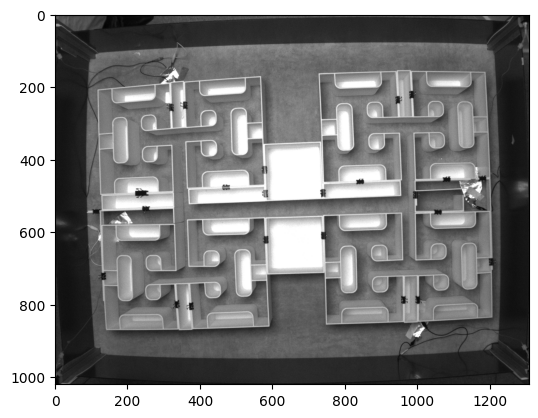

In [55]:
plt.imshow(img, cmap='gray')

# **Part 1 - Thresholding, Edge Detection, Transformations**

In [56]:
width  = img.shape[1]
height = img.shape[0]

distCoeff = np.zeros((4,1),np.float64)

k1 = -0.7e-5; # negative to remove barrel distortion
k2 = 0.0;
p1 = 0.0;
p2 = 0.0;

distCoeff[0,0] = k1;
distCoeff[1,0] = k2;
distCoeff[2,0] = p1;
distCoeff[3,0] = p2;

# assume unit matrix for camera
cam = np.eye(3,dtype=np.float32)

cam[0,2] = width/2.0  # define center x
cam[1,2] = height/2.0 # define center y
cam[0,0] = 10.        # define focal length x
cam[1,1] = 10.        # define focal length y

# here the undistortion will be computed
dst = cv2.undistort(img,cam,distCoeff)


In [57]:
aligned_dst = rotate(dst, -1.7)
aligned_img = rotate(img, -1.7)

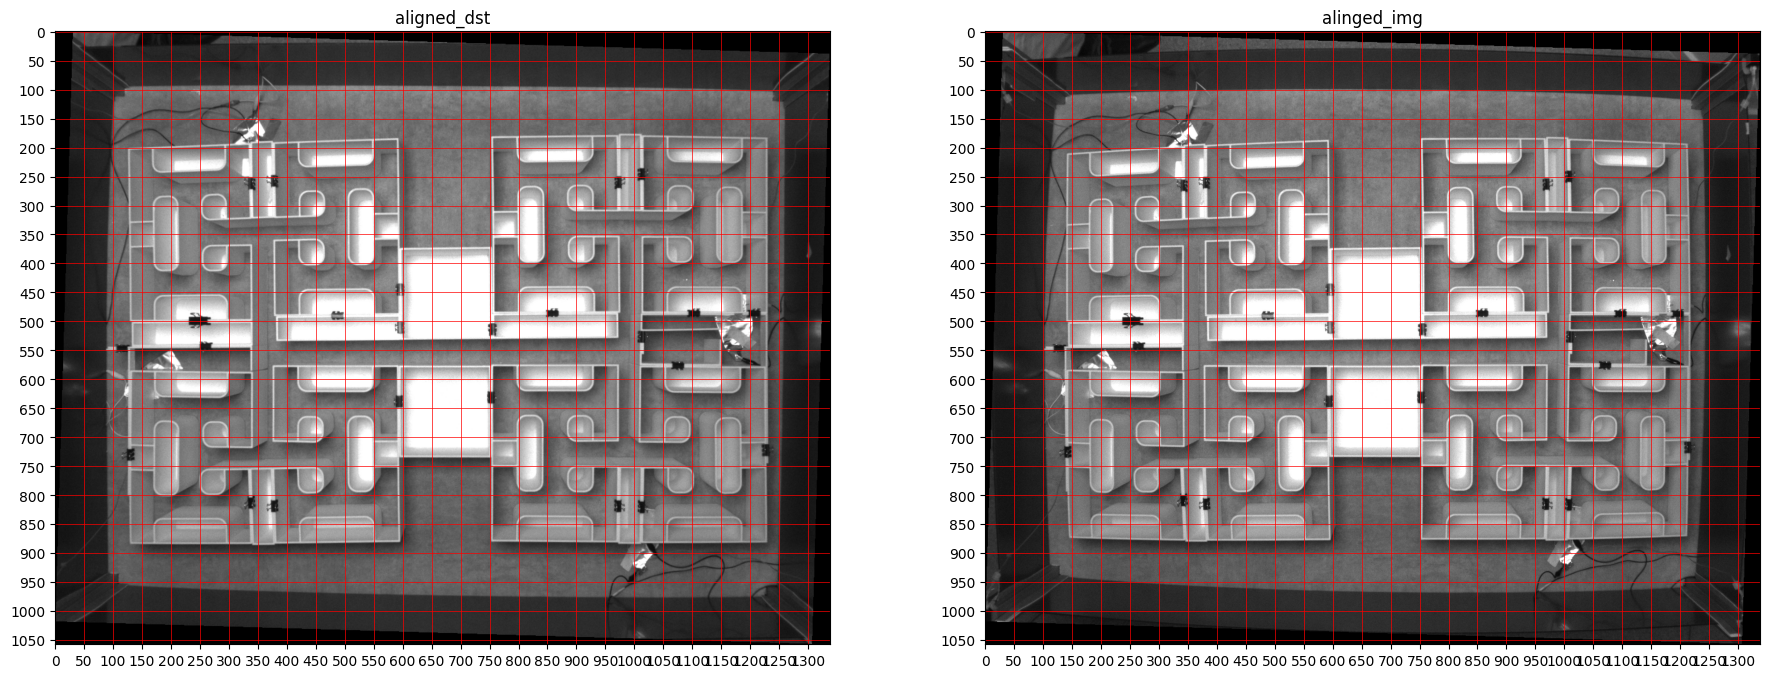

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(22, 11))

# Display 'img' image
axes[1].imshow(aligned_img, cmap='gray')
axes[1].set_title('alinged_img')
axes[1].grid(which='major', axis='both', linestyle='-', color='r', linewidth=0.5)
axes[1].set_xticks(np.arange(0, aligned_img.shape[1], 50))
axes[1].set_yticks(np.arange(0, aligned_img.shape[0], 50))
# Display 'dst' image
axes[0].imshow(aligned_dst, cmap='gray')
axes[0].set_title('aligned_dst')
axes[0].grid(which='major', axis='both', linestyle='-', color='r', linewidth=0.5)
axes[0].set_xticks(np.arange(0, aligned_dst.shape[1], 50))
axes[0].set_yticks(np.arange(0, aligned_dst.shape[0], 50))


plt.show()

In [59]:
# Create a FastLineDetector object
fld = cv2.ximgproc.createFastLineDetector(length_threshold = 11)
# Detect lines in the image
lines = fld.detect(aligned_dst)

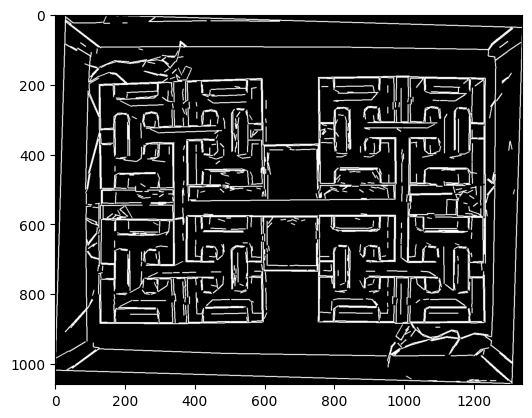

In [60]:
#Create blank image the size of aligned_dst
blank_image_for_dilate = np.zeros_like(aligned_dst)

# Draw the lines on the blank image
for line in lines:
    x0, y0, x1, y1 = map(int, line[0])
    cv2.line(blank_image_for_dilate, (x0, y0), (x1, y1), (255, 255, 255), 2)

# Display the image with detected lines
# Invert blank_image colors
blank_image = cv2.bitwise_not(blank_image_for_dilate)

plt.imshow(blank_image_for_dilate, cmap='gray')

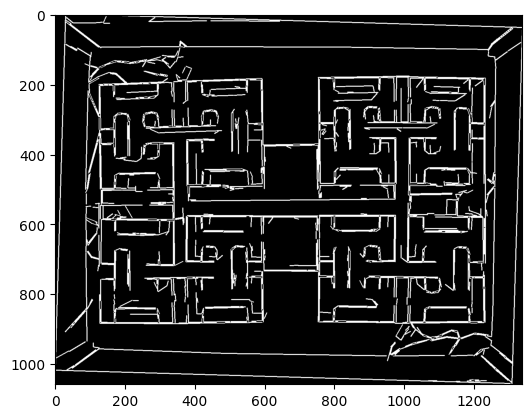

In [61]:
# Find contours in the image
contours, _ = cv2.findContours(blank_image_for_dilate, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)

# Iterate through the contours
for contour in contours:
    # Calculate the area of the contour
    area = cv2.contourArea(contour)

    # If the area is less than X pixels, remove the artifact
    if area < 250:
        cv2.drawContours(blank_image_for_dilate, [contour], -1, (0, 0, 0), -1)  # Fill the contour with white

# Display the image with artifacts removed
plt.imshow(blank_image_for_dilate, cmap='gray')

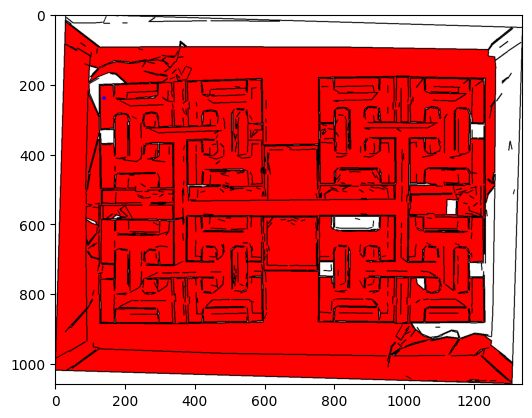

In [62]:
# Convert the blank image to a color image
blank_image_color = cv2.cvtColor(blank_image, cv2.COLOR_GRAY2BGR)

# Define the seed point and color
seed_point = (140, 240)
color = (255, 0, 0)  # Blue in BGR

# Flood fill the image
cv2.floodFill(blank_image_color, None, seed_point, color)
# Draw the seed point with red point
cv2.circle(blank_image_color, seed_point, 5, (0, 0, 255), -1)
# Display or save the image
plt.imshow(blank_image_color)

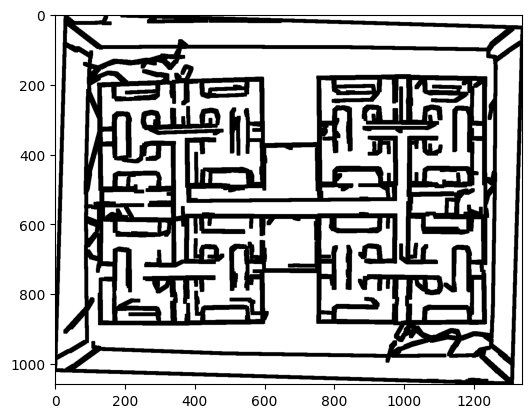

In [63]:
kernel_dilate = cv2.getStructuringElement(cv2.MORPH_RECT, (9, 9)) #(9, 9) for maze1, (7, 7) for maze2
dilated_black = cv2.morphologyEx(blank_image_for_dilate, cv2.MORPH_DILATE, kernel_dilate)
# Invert Dilated colors
dilated = cv2.bitwise_not(dilated_black)

plt.imshow(dilated, cmap='gray')

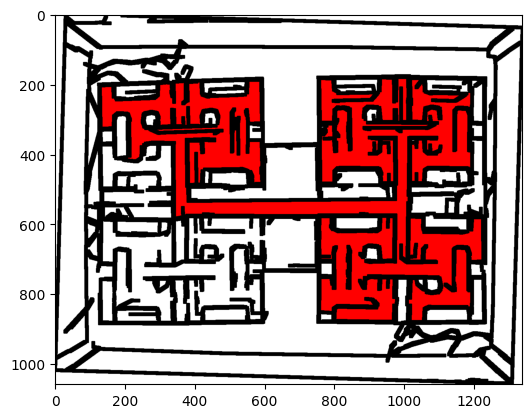

In [64]:
# Convert the blank image to a color image
dilated_image_color = cv2.cvtColor(dilated, cv2.COLOR_GRAY2BGR)

# Define the seed point and color
seed_point = (150, 250)
color = (255, 0, 0)  # Blue in BGR

# Flood fill the image
cv2.floodFill(dilated_image_color, None, seed_point, color)
# Draw the seed point with red point
# cv2.circle(dilated_image_color, seed_point, 5, (0, 0, 255), -1)
# Display or save the image
plt.imshow(dilated_image_color)

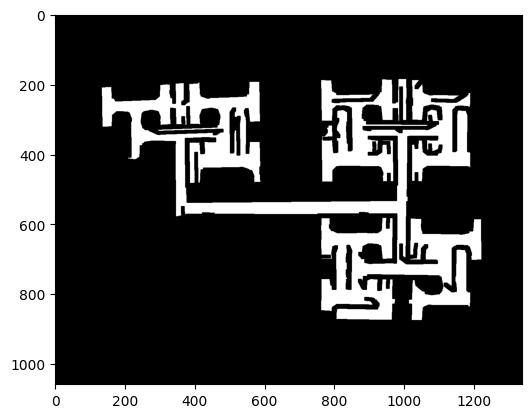

In [65]:
# Change black pixels to white in dilated_image_color
dilated_image_color[np.where((dilated_image_color == [0, 0, 0]).all(axis=2))] = [255, 255, 255]

# Convert the color image back to grayscale
dilated_image_gray = cv2.cvtColor(dilated_image_color, cv2.COLOR_BGR2GRAY)

# Threshold the image to binary
_, thresholded_image = cv2.threshold(dilated_image_gray, 127, 255, cv2.THRESH_BINARY)

# Invert thresholded_image
thresholded_image = cv2.bitwise_not(thresholded_image)

# Smooth edges
blurred = cv2.GaussianBlur(thresholded_image, (11, 11), 0)
_, refined_binary = cv2.threshold(blurred, 128, 255, cv2.THRESH_BINARY)

# Display the skeletonized image
plt.imshow(thresholded_image, cmap='gray')  

# **Part 2 - Pattern Matching**

In [6]:
# Load the image
pattern = cv2.imread('/var/home/almogmeir/Documents/M.Sc/Project/pattern.png', cv2.IMREAD_GRAYSCALE)
pattern_cut = cv2.imread('/var/home/almogmeir/Documents/M.Sc/Project/pattern_cut.png', cv2.IMREAD_GRAYSCALE)

kernel = np.ones((3, 3), np.uint8)

# Threshold the image to create a binary image
_, pattern_binary = cv2.threshold(pattern, 127, 255, cv2.THRESH_BINARY_INV)
_, pattern_cut_binary = cv2.threshold(pattern_cut, 127, 255, cv2.THRESH_BINARY_INV)


pattern_dilated_binary = cv2.dilate(pattern_cut_binary, kernel, iterations=1)
_, pattern_dilated_binary = cv2.threshold(pattern_dilated_binary, 127, 255, cv2.THRESH_BINARY)


# Resize the image to 218 pixels height, currently fixed but will be according
# to the affine transformation
height = 218
width = int(pattern_binary.shape[1] * height / pattern_binary.shape[0])
pattern_binary = cv2.resize(pattern_binary, (width, height), interpolation=cv2.INTER_AREA)
pattern_dilated_binary = cv2.resize(pattern_dilated_binary, (width, height), interpolation=cv2.INTER_AREA)


rotations = []
rotations_dilated = []

for angle in range(0, 360, 90):
  rotations.append(rotate(pattern_binary, angle, reshape=True))
  # Dilate the pattern a bit to make the lines stronger
  rotations_dilated.append(rotate(pattern_dilated_binary, angle, reshape=True))


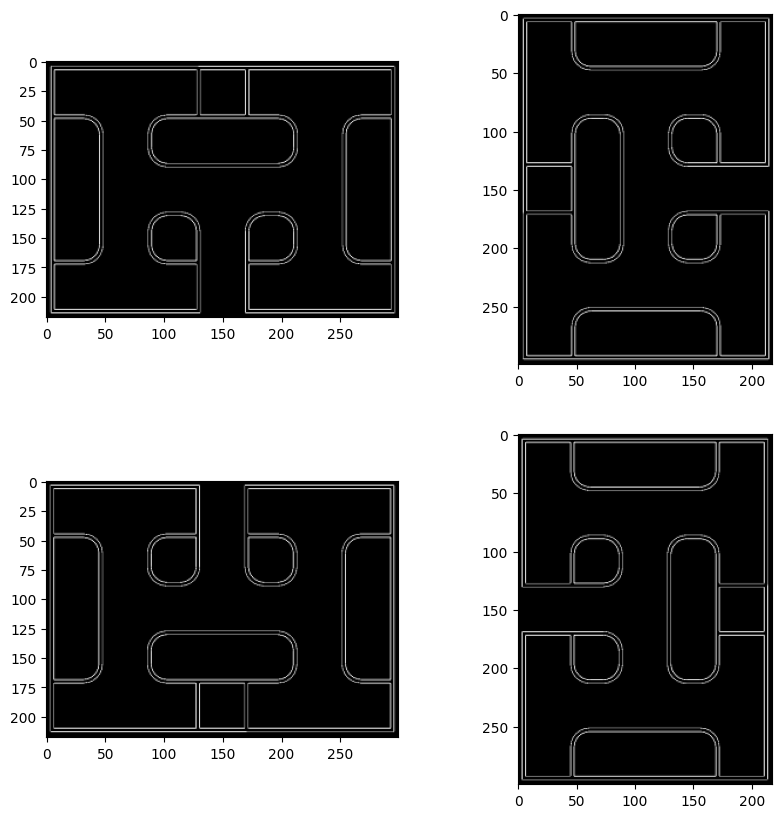

In [65]:
# Display the 4 rotations with plt
plt.figure(figsize=(10, 10))



for i in range(len(rotations)):
  plt.subplot(2, 2, i + 1)
  plt.imshow(rotations[i], cmap='gray')

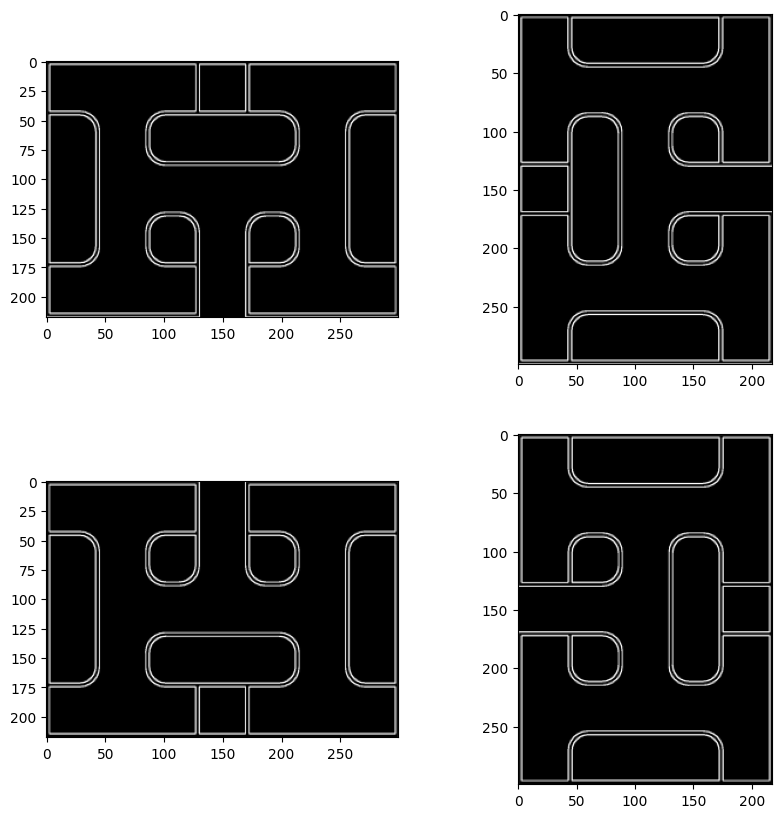

In [67]:
# Display the 4 rotations with plt
plt.figure(figsize=(10, 10))



for i in range(len(rotations_dilated)):
  plt.subplot(2, 2, i + 1)
  plt.imshow(rotations_dilated[i], cmap='gray')

In [51]:
pattern_binary.shape

(218, 300)

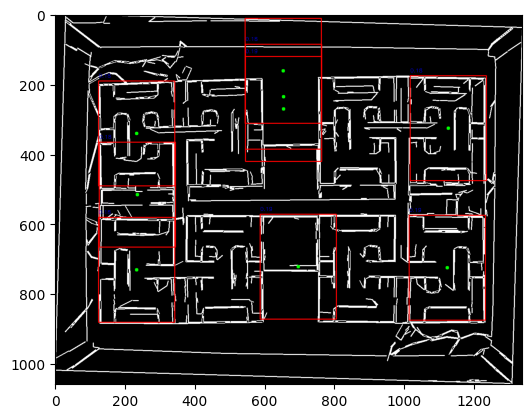

In [52]:
def get_overlap_count(matches, match, template_shape):
    """
    Count how many existing matches overlap with the given match.

    Args:
        matches: List of top-left corners of matches.
        match: Top-left corner of the match to check.
        template_shape: Shape of the template (height, width).

    Returns:
        The number of matches that overlap with the given match.
    """
    new_rect = [match[0], match[1], match[0] + template_shape[1], match[1] + template_shape[0]]
    overlap_count = 0

    for existing in matches:
        existing_rect = [existing[0], existing[1], existing[0] + template_shape[1], existing[1] + template_shape[0]]
        # Check if rectangles overlap
        if not (new_rect[2] <= existing_rect[0] or  # new right <= existing left
                new_rect[0] >= existing_rect[2] or  # new left >= existing right
                new_rect[3] <= existing_rect[1] or  # new bottom <= existing top
                new_rect[1] >= existing_rect[3]):   # new top >= existing bottom
            overlap_count += 1

    return overlap_count

def filter_close_points(points, distance_threshold, min_samples=2):
    """
    Remove points that are closer than the distance_threshold and exclude clusters smaller than min_samples.

    Args:
        points: List of (x, y) tuples representing locations.
        distance_threshold: Minimum allowable distance between points (for clustering).
        min_samples: Minimum number of points in a cluster to keep it.

    Returns:
        Filtered list of points.
    """
    if len(points) == 0:
        return []

    # Convert points to numpy array
    points_array = np.array(points)

    # Apply DBSCAN clustering
    clustering = DBSCAN(eps=distance_threshold, min_samples=min_samples).fit(points_array)

    # Filter points: Keep clusters with at least min_samples points
    filtered_points = []
    for cluster_label in set(clustering.labels_):
        if cluster_label == -1:
            continue  # Ignore noise (label -1)

        # Get all points in this cluster
        cluster_points = points_array[clustering.labels_ == cluster_label]

        # Only process clusters with enough points
        if len(cluster_points) >= min_samples:
            # Remove points that are too close within the cluster
            cluster_filtered = []
            for pt in cluster_points:
                if all(np.linalg.norm(pt - np.array(fp)) > distance_threshold for fp in cluster_filtered):
                    cluster_filtered.append(pt)
            filtered_points.extend(cluster_filtered)

    # Convert to list of tuples
    return [tuple(pt) for pt in filtered_points]


def filter_close_points_post(points, distance_threshold):
    """
    Remove points that are closer than the distance_threshold.

    Args:
        points: List of (x, y) tuples representing locations.
        distance_threshold: Minimum allowable distance between points.

    Returns:
        Filtered list of points.
    """
    filtered_points = []
    for pt in points:
        # Check if this point is far enough from all already-kept points
        if all(np.linalg.norm(np.array(pt) - np.array(fp)) > distance_threshold for fp in filtered_points):
            filtered_points.append(pt)
    return filtered_points


def match_template(img, template):
    result = cv2.matchTemplate(img, template, cv2.TM_CCOEFF_NORMED)
    return result

# Clone blank_image_for_dilate to preserve the original
matches = blank_image_for_dilate.copy()
distance_threshold = 30

for template in rotations:
    res = match_template(matches, template)
    loc = np.where(res >= 0.18)  # Adjust the threshold as needed
    # Create a list of (x, y) points from loc
    points = list(zip(*loc[::-1]))

    # Filter points to remove close duplicates
    filtered_points = filter_close_points(points, distance_threshold, 10)

    # Convert to RGB for drawing (after template matching)
    matches_rgb = cv2.cvtColor(matches, cv2.COLOR_GRAY2RGB)

    # Draw points in the center of the matched regions
    for pt in filtered_points:
        # print(f"Drawing at: {pt}")
        cv2.circle(matches_rgb, (pt[0] + template.shape[1] // 2, pt[1] + template.shape[0] // 2), 5, (0, 255, 0), -1)

    # Draw rectangles around the matched regions
    for pt in filtered_points:
        top_left = pt
        bottom_right = (pt[0] + template.shape[1], pt[1] + template.shape[0])
        # print(f"Rectangle: {top_left} to {bottom_right}")
        cv2.rectangle(matches_rgb, top_left, bottom_right, (255, 0, 0), 2)

        # Add probability text
        probability = res[pt[1], pt[0]]
        cv2.putText(matches_rgb, f"{probability:.2f}", (pt[0], pt[1] - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1)

plt.imshow(matches_rgb)

points: [(np.int64(83), np.int64(539)), (np.int64(84), np.int64(539)), (np.int64(85), np.int64(539)), (np.int64(86), np.int64(539)), (np.int64(87), np.int64(539)), (np.int64(82), np.int64(540)), (np.int64(83), np.int64(540)), (np.int64(84), np.int64(540)), (np.int64(85), np.int64(540)), (np.int64(86), np.int64(540)), (np.int64(87), np.int64(540)), (np.int64(81), np.int64(541)), (np.int64(82), np.int64(541)), (np.int64(83), np.int64(541)), (np.int64(84), np.int64(541)), (np.int64(85), np.int64(541)), (np.int64(86), np.int64(541)), (np.int64(87), np.int64(541)), (np.int64(81), np.int64(542)), (np.int64(82), np.int64(542)), (np.int64(83), np.int64(542)), (np.int64(84), np.int64(542)), (np.int64(85), np.int64(542)), (np.int64(86), np.int64(542)), (np.int64(87), np.int64(542)), (np.int64(81), np.int64(543)), (np.int64(82), np.int64(543)), (np.int64(83), np.int64(543)), (np.int64(84), np.int64(543)), (np.int64(85), np.int64(543)), (np.int64(86), np.int64(543)), (np.int64(87), np.int64(543)),

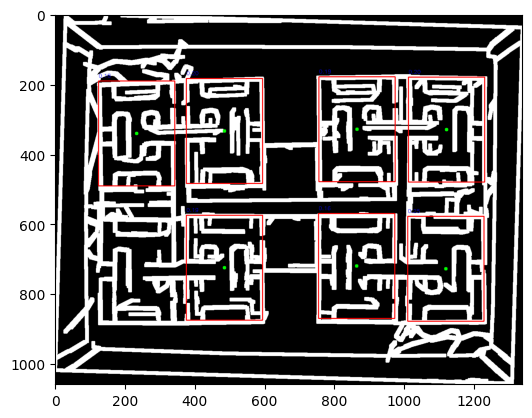

In [53]:
# Clone blank_image_for_dilate to preserve the original
matches = dilated_black.copy()
distance_threshold = 20
filtered_points = []

for i, template in enumerate(rotations):
    res = match_template(matches, template)
    loc = np.where(res >= 0.19)  # Adjust the threshold as needed
    # Create a list of (x, y) points from loc
    points = list(zip(*loc[::-1]))
    print(f'points: {points}')

    # Filter points to remove close duplicates
    curr_filtered_points = filter_close_points(points, distance_threshold, 10)
    filtered_points.extend(curr_filtered_points)

print(f'filtered points length: {len(filtered_points)}')
print(f'filtered points: {filtered_points}')

filtered_points = filter_close_points_post(filtered_points, 10)
print(f'filtered points length: {len(filtered_points)}')
print(f'filtered points: {filtered_points}')

# # Remove matches that overlap with 2 or more other matches
final_matches = []
for m in filtered_points:
  overlap_count = get_overlap_count(filtered_points, m, template.shape)
  # print(f'overlap count is: {overlap_count}')
  if overlap_count < 4:  # Keep matches with less than 3 overlaps
      final_matches.append(m)
print(f'final matches length: {len(final_matches)}')
print(f'final matches: {final_matches}')
# Convert to RGB for drawing
matches_rgb = cv2.cvtColor(matches, cv2.COLOR_GRAY2RGB)

# Draw points in the center of the matched regions
for pt in final_matches:
    # print(f"Drawing at: {pt}")
    cv2.circle(matches_rgb, (pt[0] + template.shape[1] // 2, pt[1] + template.shape[0] // 2), 5, (0, 255, 0), -1)

# Draw rectangles around the matched regions
for pt in final_matches:
    top_left = pt
    bottom_right = (pt[0] + template.shape[1], pt[1] + template.shape[0])
    # print(f"Rectangle: {top_left} to {bottom_right}")
    cv2.rectangle(matches_rgb, top_left, bottom_right, (255, 0, 0), 2)

    # Add probability text
    probability = res[pt[1], pt[0]]
    cv2.putText(matches_rgb, f"{probability:.2f}", (pt[0], pt[1] - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1)

plt.imshow(matches_rgb)

points: [(np.int64(83), np.int64(539)), (np.int64(84), np.int64(539)), (np.int64(85), np.int64(539)), (np.int64(86), np.int64(539)), (np.int64(87), np.int64(539)), (np.int64(82), np.int64(540)), (np.int64(83), np.int64(540)), (np.int64(84), np.int64(540)), (np.int64(85), np.int64(540)), (np.int64(86), np.int64(540)), (np.int64(87), np.int64(540)), (np.int64(81), np.int64(541)), (np.int64(82), np.int64(541)), (np.int64(83), np.int64(541)), (np.int64(84), np.int64(541)), (np.int64(85), np.int64(541)), (np.int64(86), np.int64(541)), (np.int64(87), np.int64(541)), (np.int64(81), np.int64(542)), (np.int64(82), np.int64(542)), (np.int64(83), np.int64(542)), (np.int64(84), np.int64(542)), (np.int64(85), np.int64(542)), (np.int64(86), np.int64(542)), (np.int64(87), np.int64(542)), (np.int64(81), np.int64(543)), (np.int64(82), np.int64(543)), (np.int64(83), np.int64(543)), (np.int64(84), np.int64(543)), (np.int64(85), np.int64(543)), (np.int64(86), np.int64(543)), (np.int64(87), np.int64(543)),

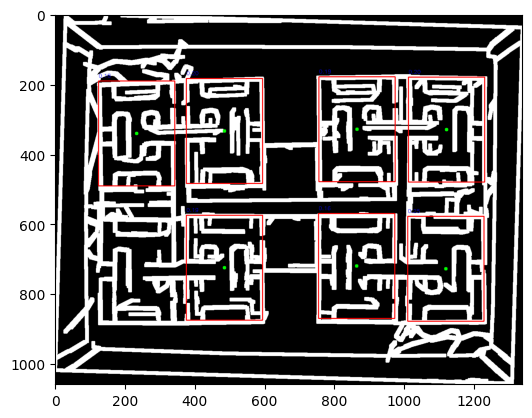

In [54]:
# Clone blank_image_for_dilate to preserve the original
matches = dilated_black.copy()
distance_threshold = 20
filtered_points = []

for template in rotations:
    res = match_template(matches, template)
    loc = np.where(res >= 0.19)  # Adjust the threshold as needed
    # Create a list of (x, y) points from loc
    points = list(zip(*loc[::-1]))
    print(f'points: {points}')

    # Filter points to remove close duplicates
    curr_filtered_points = filter_close_points(points, distance_threshold, 10)
    filtered_points.extend(curr_filtered_points)
    print(f'curr filtered points length: {len(curr_filtered_points)}')

print(f'filtered points length: {len(filtered_points)}')
print(f'filtered points: {filtered_points}')

filtered_points = filter_close_points_post(filtered_points, 10)
print(f'filtered points length: {len(filtered_points)}')
print(f'filtered points: {filtered_points}')

# # Remove matches that overlap with 2 or more other matches
final_matches = []
for m in filtered_points:
  overlap_count = get_overlap_count(filtered_points, m, template.shape)
  # print(f'overlap count is: {overlap_count}')
  if overlap_count < 4:  # Keep matches with less than 3 overlaps
      final_matches.append(m)
print(f'final matches length: {len(final_matches)}')
print(f'final matches: {final_matches}')
# Convert to RGB for drawing
# matches_rgb = cv2.cvtColor(matches, cv2.COLOR_GRAY2RGB)

# Draw points in the center of the matched regions
for pt in final_matches:
    # print(f"Drawing at: {pt}")
    cv2.circle(matches_rgb, (pt[0] + template.shape[1] // 2, pt[1] + template.shape[0] // 2), 5, (0, 255, 0), -1)

# Draw rectangles around the matched regions
for pt in final_matches:
    top_left = pt
    bottom_right = (pt[0] + template.shape[1], pt[1] + template.shape[0])
    # print(f"Rectangle: {top_left} to {bottom_right}")
    cv2.rectangle(matches_rgb, top_left, bottom_right, (255, 0, 0), 2)

    # Add probability text
    probability = res[pt[1], pt[0]]
    cv2.putText(matches_rgb, f"{probability:.2f}", (pt[0], pt[1] - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1)

plt.imshow(matches_rgb)

Points for template 0: [(np.int64(86), np.int64(540), 0), (np.int64(85), np.int64(541), 0), (np.int64(86), np.int64(541), 0), (np.int64(83), np.int64(542), 0), (np.int64(84), np.int64(542), 0), (np.int64(85), np.int64(542), 0), (np.int64(86), np.int64(542), 0), (np.int64(83), np.int64(543), 0), (np.int64(84), np.int64(543), 0), (np.int64(85), np.int64(543), 0), (np.int64(86), np.int64(543), 0), (np.int64(83), np.int64(544), 0), (np.int64(84), np.int64(544), 0), (np.int64(85), np.int64(544), 0), (np.int64(86), np.int64(544), 0)]
Current filtered points length (template 0): 1
Points for template 1: [(np.int64(754), np.int64(180), 1), (np.int64(755), np.int64(180), 1), (np.int64(753), np.int64(181), 1), (np.int64(754), np.int64(181), 1), (np.int64(755), np.int64(181), 1), (np.int64(756), np.int64(181), 1), (np.int64(755), np.int64(182), 1), (np.int64(1010), np.int64(182), 1), (np.int64(1011), np.int64(182), 1), (np.int64(1012), np.int64(182), 1), (np.int64(1013), np.int64(182), 1), (np.in

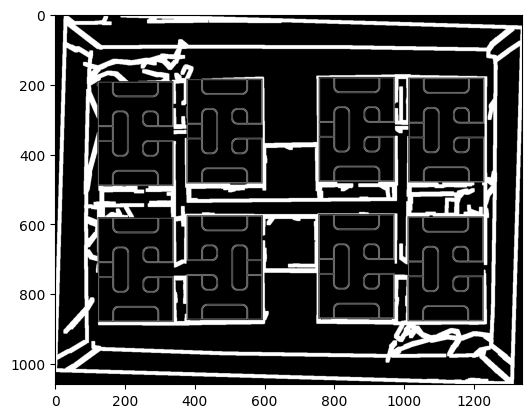

In [59]:
# Clone blank_image_for_dilate to preserve the original
matches = dilated_black.copy()
patterns_drawn = dilated_black.copy()
distance_threshold = 20
filtered_points_with_template = []

for template_index, template in enumerate(rotations):
    res = match_template(matches, template)
    loc = np.where(res >= 0.205)  # Adjust the threshold as needed
    # Create a list of (x, y, template_index) tuples
    points_with_template = [(x, y, template_index) for x, y in zip(*loc[::-1])]
    print(f'Points for template {template_index}: {points_with_template}')

    # Filter points to remove close duplicates
    curr_filtered_points_with_template = filter_close_points(
        points_with_template, distance_threshold, 10
    )
    filtered_points_with_template.extend(curr_filtered_points_with_template)
    print(f'Current filtered points length (template {template_index}): {len(curr_filtered_points_with_template)}')

print(f'Total filtered points length: {len(filtered_points_with_template)}')
print(f'Total filtered points: {filtered_points_with_template}')

# Perform post-filtering to remove very close matches
filtered_points_with_template = filter_close_points_post(
    filtered_points_with_template, 10
)
print(f'Post-filtered points length: {len(filtered_points_with_template)}')
print(f'Post-filtered points: {filtered_points_with_template}')

# Remove matches that overlap with 2 or more other matches
final_matches_with_template = []
for match in filtered_points_with_template:
    x, y, template_index = match
    overlap_count = get_overlap_count(
        [(m[0], m[1]) for m in filtered_points_with_template], (x, y), rotations[template_index].shape
    )
    if overlap_count < 4:  # Keep matches with less than 4 overlaps
        final_matches_with_template.append(match)
print(f'Final matches length: {len(final_matches_with_template)}')
print(f'Final matches: {final_matches_with_template}')

# Replace the corresponding parts in the image with the correct rotation of the template
for x, y, template_index in final_matches_with_template:
    template = rotations_dilated[template_index]
    h, w = template.shape
    # Replace the region in the patterns_drawn image with the rotated template
    patterns_drawn[y:y + h, x:x + w] = template
    print(f'Placed template {template_index} at ({x}, {y})')

# Display the result
plt.imshow(patterns_drawn, cmap='gray')

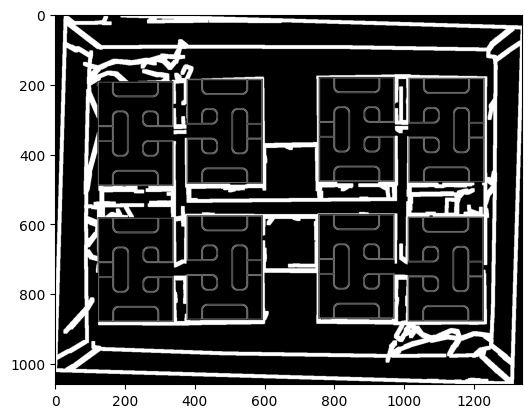

In [60]:
# Manual fix of patterns_drawn for maze1, treshold 0.23

# # Replace template 1 at (379, 540) with template 3
# patterns_drawn[540:540 + 300, 379:379 + 218] = rotations_dilated[3]
# # Replace template 1 at (899, 540) with template 3
# patterns_drawn[540:540 + 300, 899:899 + 218] = rotations_dilated[3]
# # Display the result
# plt.imshow(patterns_drawn, cmap='gray')

# Manual fix of patterns_drawn for maze2, treshold 0.205

# Replace template 1 at (1010, 182) with template 3
patterns_drawn[182:182 + 300, 1010:1010 + 218] = rotations_dilated[3]
# Replace template 1 at (1008, 579)with template 3
patterns_drawn[579:579 + 300, 1008:1008 + 218] = rotations_dilated[3]

# (376, 185)
patterns_drawn[185:185 + 300, 376:376 + 218] = rotations_dilated[3]


# Draw a black rectangle between (340, 570) and (360, 570) (open clogged path)
# cv2.rectangle(patterns_drawn, (340, 570), (371, 572), (0, 0, 0), -1)

# Export the image
cv2.imwrite('/var/home/almogmeir/Documents/M.Sc/Project/patterns_drawn.png', patterns_drawn)

plt.imshow(patterns_drawn, cmap='gray')



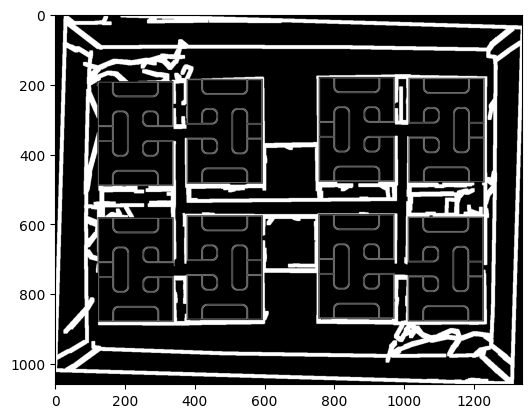

In [32]:
# Import the fixed image
patterns_drawn = cv2.imread('/var/home/almogmeir/Documents/M.Sc/Project/patterns_drawn_fixed.png', cv2.IMREAD_GRAYSCALE)

plt.imshow(patterns_drawn, cmap='gray')



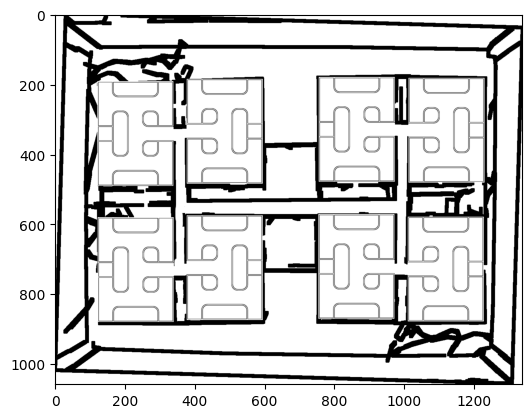

In [36]:
# Define the seed point and color
seed_point = (150, 250)
color = (255, 0, 0)  # Blue in BGR

# Invert Dilated colors
patterns_drawn_inverted = cv2.bitwise_not(patterns_drawn)
# Convert the blank image to a color image
patterns_drawn_color = cv2.cvtColor(patterns_drawn_inverted, cv2.COLOR_GRAY2BGR)
plt.imshow(patterns_drawn_color)

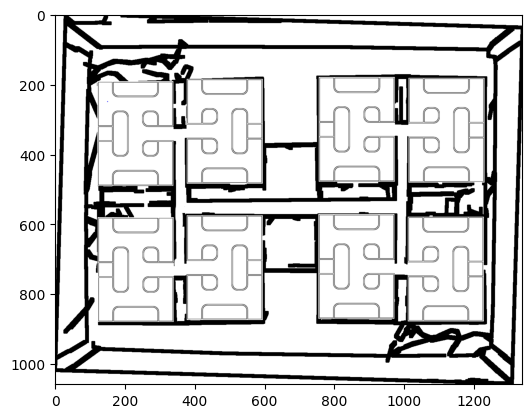

In [34]:
# Draw the seed point on patterns_drawn_color in red
cv2.circle(patterns_drawn_color, seed_point, 1, (0, 0, 255), -1)
plt.imshow(patterns_drawn_color)

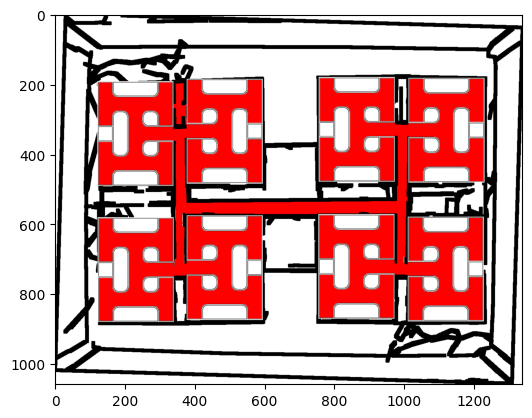

In [37]:
# Flood fill the image
cv2.floodFill(patterns_drawn_color, None, seed_point, color)
# Draw the seed point with red point
# cv2.circle(dilated_image_color, seed_point, 5, (0, 0, 255), -1)
# Display or save the image
plt.imshow(patterns_drawn_color)

# Part 3 - Tiling & Graph extraction

In [38]:
def is_tile_blue(tile, threshold=0.5):
    """
    Determine if a tile is mostly blue.

    Parameters:
    - tile: Numpy array representing the tile.
    - threshold: Proportion of blue pixels required to label the tile as part of the graph.

    Returns:
    - True if the tile is mostly blue, False otherwise.
    """
    # Calculate the proportion of blue pixels
    blue_pixels = (tile[:, :, 2] > 150) & (tile[:, :, 2] > tile[:, :, 1]) & (tile[:, :, 2] > tile[:, :, 0])
    proportion_blue = np.sum(blue_pixels) / (tile.shape[0] * tile.shape[1])
    return proportion_blue > threshold

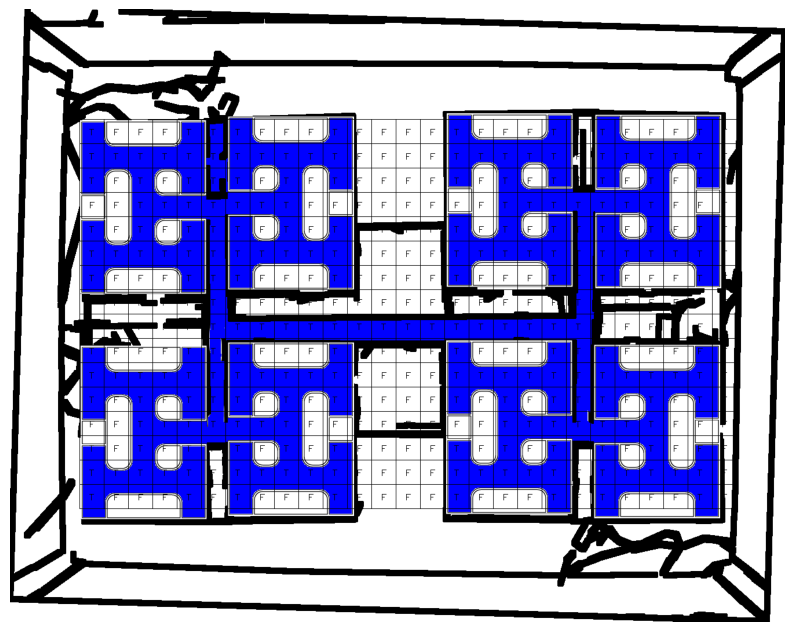

In [39]:
def label_maze_with_text(image, tile_size=42, threshold=0.45, maze_borders=None):
    """
    Split the maze image into tiles, label them, and visualize the result with text labels.

    Parameters:
    - image_path: Path to the maze image.
    - tile_size: Size of each tile (tile_size x tile_size).
    - threshold: Proportion of blue pixels to determine if a tile is part of the graph.
    - maze_borders: List of 4 coordinates [x_min, y_min, x_max, y_max] defining the borders of the maze.
    """
    # Load image
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Convert BGR to RGB
    height, width, _ = image.shape

    # Create a copy of the image for visualization
    labeled_image = image.copy()

    # Define maze boundaries
    if maze_borders:
        x_min, y_min, x_max, y_max = maze_borders
    else:
        x_min, y_min, x_max, y_max = 0, 0, width, height

    for y in range(y_min, y_max, tile_size):
        for x in range(x_min, x_max, tile_size):
            tile = image[y:y+tile_size, x:x+tile_size]
            if tile.shape[0] == tile_size and tile.shape[1] == tile_size:  # Ensure full tile
                is_graph = is_tile_blue(tile, threshold)
                label = "T" if is_graph else "F"

                # Put label text on the tile
                font_scale = 0.5
                thickness = 1
                # color = (0, 255, 0) if is_graph else (255, 0, 0)  # Green for graph, Red for not graph
                text_size = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, font_scale, thickness)[0]
                text_x = x + (tile_size - text_size[0]) // 2
                text_y = y + (tile_size + text_size[1]) // 2

                cv2.putText(labeled_image, label, (text_x, text_y), cv2.FONT_HERSHEY_SIMPLEX, font_scale, (0, 0, 0), thickness)
                # add border to the tile
                cv2.rectangle(labeled_image, (x, y), (x+tile_size, y+tile_size), (0, 0, 0), 1)

    # Display the result
    plt.figure(figsize=(10, 10))
    plt.imshow(labeled_image)
    plt.axis("off")
    plt.show()

# Usage
# maze1_borders = [130, 203, 1116, 837]
# label_maze_with_text(patterns_drawn_color, maze_borders=maze1_borders)

maze2_borders = [120, 190, 1216, 844]
label_maze_with_text(patterns_drawn_color, maze_borders=maze2_borders)

In [40]:
def get_maze_tiles(image, tile_size=42, threshold=0.45, maze_borders=None):
    """
    Split the maze image into tiles, return list of tiles that are part of the graph.

    """

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Convert BGR to RGB
    height, width, _ = image.shape

    # Define maze boundaries
    if maze_borders:
        x_min, y_min, x_max, y_max = maze_borders
    else:
        x_min, y_min, x_max, y_max = 0, 0, width, height

    graph_tiles = []
    for y in range(y_min, y_max, tile_size):
        for x in range(x_min, x_max, tile_size):
            tile = image[y:y+tile_size, x:x+tile_size]
            if tile.shape[0] == tile_size and tile.shape[1] == tile_size:  # Ensure full tile
                is_graph = is_tile_blue(tile, threshold)
                # (coordinates, is_graph, borders[right,down,left,up])
                # Append tile data as a dictionary
                graph_tiles.append({
                    'coordinates': (x // tile_size, y // tile_size),
                    'is_graph': is_graph,
                    'borders': [False, False, False, False]
                })
    graph_tiles = pd.DataFrame(graph_tiles)
    graph_tiles = graph_tiles.sort_values(by=['coordinates'], key=lambda col: col.apply(lambda x: (x[0], x[1])))
    # Re-index the df
    graph_tiles = graph_tiles.reset_index(drop=True)

    return graph_tiles

In [42]:
# maze1_borders = [130, 203, 1116, 837]
tiles = get_maze_tiles(patterns_drawn_color, maze_borders=maze2_borders)
tiles
#'borders': {'right':False, 'down':False, 'left':False, 'up':False}

,coordinates,is_graph,borders
0,"(2, 4)",True,"[False, False, False, False]"
1,"(2, 5)",True,"[False, False, False, False]"
2,"(2, 6)",True,"[False, False, False, False]"
3,"(2, 7)",False,"[False, False, False, False]"
4,"(2, 8)",True,"[False, False, False, False]"
...,...,...,...
427,"(28, 15)",False,"[False, False, False, False]"
428,"(28, 16)",False,"[False, False, False, False]"
429,"(28, 17)",False,"[False, False, False, False]"
430,"(28, 18)",False,"[False, False, False, False]"


In [62]:
# Manual fix tile labeling for maze1

# # update tile where coordinates are (25,12), (25,16), (25,10), (25,6) to be a graph tile
# tiles.loc[(tiles['coordinates'] == (25, 12)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (25, 16)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (25, 10)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (25, 6)), 'is_graph'] = True


# # (24, 8), (22, 8), (22,6), (22, 4) are not part of the graph
# tiles.loc[(tiles['coordinates'] == (24, 8)), 'is_graph'] = False
# tiles.loc[(tiles['coordinates'] == (22, 8)), 'is_graph'] = False
# tiles.loc[(tiles['coordinates'] == (22, 6)), 'is_graph'] = False
# tiles.loc[(tiles['coordinates'] == (22, 4)), 'is_graph'] = False

# Manual fix tile labeling for maze2

# update tile where coordinates are (25,4) to be a graph tile
tiles.loc[(tiles['coordinates'] == (27, 10)), 'is_graph'] = True
tiles.loc[(tiles['coordinates'] == (27, 6)), 'is_graph'] = True
tiles.loc[(tiles['coordinates'] == (7, 7)), 'is_graph'] = True
tiles.loc[(tiles['coordinates'] == (7, 12)), 'is_graph'] = True
tiles.loc[(tiles['coordinates'] == (22, 14)), 'is_graph'] = True
tiles.loc[(tiles['coordinates'] == (22, 15)), 'is_graph'] = True
tiles.loc[(tiles['coordinates'] == (27, 17)), 'is_graph'] = True
tiles.loc[(tiles['coordinates'] == (27, 13)), 'is_graph'] = True


tiles.loc[(tiles['coordinates'] == (24, 4)), 'is_graph'] = False
tiles.loc[(tiles['coordinates'] == (24, 8)), 'is_graph'] = False
tiles.loc[(tiles['coordinates'] == (26, 8)), 'is_graph'] = False
tiles.loc[(tiles['coordinates'] == (7, 17)), 'is_graph'] = False
tiles.loc[(tiles['coordinates'] == (7, 18)), 'is_graph'] = False
tiles.loc[(tiles['coordinates'] == (7, 19)), 'is_graph'] = False

#
tiles.loc[(tiles['coordinates'] == (7, 4)), 'is_graph'] = False
tiles.loc[(tiles['coordinates'] == (7, 5)), 'is_graph'] = False
tiles.loc[(tiles['coordinates'] == (7, 6)), 'is_graph'] = False



In [63]:
def find_and_update_pattern(tiles_df, pattern):
    """
    Given a DataFrame of tiles and a pattern (list of lists), find any occurrence of the pattern,
    horizontally or vertically, in the tiles, and update the borders according to the pattern.

    Args:
    - tiles_df (pd.DataFrame): DataFrame containing tile information with 'coordinates' and 'is_graph' columns.
    - pattern (list of lists): Pattern to find in the tiles.

    Returns:
    - Updated tiles_df.
    """
    pattern_height = len(pattern)
    pattern_width = len(pattern[0])

    # Create a 2D grid from the DataFrame for easy pattern matching
    grid = {}
    for idx, row in tiles_df.iterrows():
        grid[row['coordinates']] = row['is_graph']

    # Function to check for pattern match
    def check_pattern(x, y, pattern, grid):
        for dy in range(len(pattern)):
            for dx in range(len(pattern[0])):
                coord = (x + dx, y + dy)
                if coord not in grid or grid[coord] != pattern[dy][dx]:
                    return False
        return True

    # Function to update borders according to the pattern
    def update_borders(x, y, pattern, tiles_df):
        for dy in range(len(pattern)):
            for dx in range(len(pattern[0])):
                coord = (x + dx, y + dy)
                if pattern[dy][dx]:  # Only update borders for 'True' tiles in the pattern
                    tile_idx = tiles_df[(tiles_df['coordinates'] == coord) & (tiles_df['is_graph'] == True)].index
                    if not tile_idx.empty:
                        borders = [True, True, True, True]  # Initialize all borders to True
                        # Check each direction and update borders
                        if dy == 0 or not pattern[dy - 1][dx]:  # Top border
                            borders[0] = True
                        else:
                            borders[0] = False
                        if dy == len(pattern) - 1 or not pattern[dy + 1][dx]:  # Bottom border
                            borders[2] = True
                        else:
                            borders[2] = False
                        if dx == 0 or not pattern[dy][dx - 1]:  # Left border
                            borders[3] = True
                        else:
                            borders[3] = False
                        if dx == len(pattern[0]) - 1 or not pattern[dy][dx + 1]:  # Right border
                            borders[1] = True
                        else:
                            borders[1] = False
                        
                        # Handle the edge case for the entry point
                        # borders[right,down,left,up])
                        if dy == 3 and all(pattern[i][dx] for i in range(7)):  # Middle row in the column where all 7 tiles are True
                            if pattern == patterns[0]:  # Original pattern
                                borders[2] = False  # No bottom border
                                borders[1] = True  # Right border
                                borders[3] = True  # Left border
                            elif pattern == patterns[1]:  # 90 degrees rotation
                                borders[3] = False  # No left border
                                borders[2] = True  # Bottom border
                                borders[0] = True # Top border
                            elif pattern == patterns[2]:  # 180 degrees rotation
                                borders[0] = False  # No top border
                                borders[1] = True  # Right border
                                borders[3] = True  # Left border
                            elif pattern == patterns[3]:  # 270 degrees rotation
                                borders[1] = False  # No right border
                                borders[2] = True  # Bottom border
                                borders[0] = True # Top border

                        tiles_df.at[tile_idx[0], 'borders'] = borders

    # Function to rotate pattern 90 degrees clockwise
    def rotate_pattern(pattern):
        return [list(row) for row in zip(*pattern[::-1])]

    # Generate all four rotations of the pattern
    patterns = [pattern]
    for _ in range(3):
        patterns.append(rotate_pattern(patterns[-1]))

    # Check for matches for all rotations
    for pat in patterns:
        pat_height = len(pat)
        pat_width = len(pat[0])
        for y in range(tiles_df['coordinates'].apply(lambda x: x[1]).max() - pat_height + 2):
            for x in range(tiles_df['coordinates'].apply(lambda x: x[0]).max() - pat_width + 2):
                if check_pattern(x, y, pat, grid):
                    update_borders(x, y, pat, tiles_df)

    return tiles_df

pattern = [[True, True, True, False, True, True, True],
  [False, True, False, False, False, True, False],
  [False, True, True, True, True, True, False],
  [False, True, False, True, False, True, False],
  [True, True, True, True, True, True, True]]

pattern_height = len(pattern[0])
pattern_width = len(pattern)

test_tiles = find_and_update_pattern(tiles, pattern)
test_tiles

,coordinates,is_graph,borders
0,"(2, 4)",True,"[True, True, False, True]"
1,"(2, 5)",True,"[False, False, False, True]"
2,"(2, 6)",True,"[False, True, True, True]"
3,"(2, 7)",False,"[False, False, False, False]"
4,"(2, 8)",True,"[True, True, False, True]"
...,...,...,...
427,"(28, 15)",False,"[False, False, False, False]"
428,"(28, 16)",False,"[False, False, False, False]"
429,"(28, 17)",False,"[False, False, False, False]"
430,"(28, 18)",False,"[False, False, False, False]"


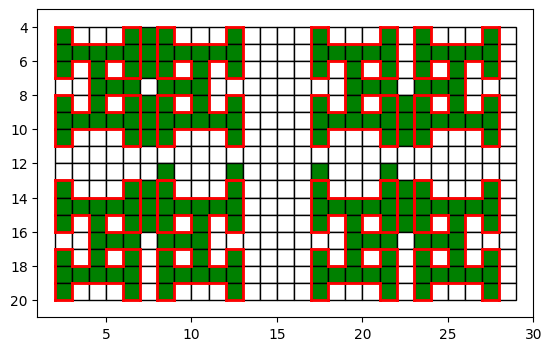

In [64]:
def visualize_tiles(tiles_df):
    """
    Visualize the tiles with green color for graph tiles that are part of the pattern and red borders for tiles in the pattern.

    Args:
    - tiles_df (pd.DataFrame): DataFrame containing tile information with 'coordinates', 'is_graph', and 'borders' columns.
    """
    fig, ax = plt.subplots()
    for idx, row in tiles_df.iterrows():
        x, y = row['coordinates']
        color = 'green' if row['borders'] != [False, False, False, False] else 'white'
        rect = plt.Rectangle((x, y), 1, 1, facecolor=color, edgecolor='black')
        ax.add_patch(rect)
        
        # Draw red borders for tiles in the pattern
        if row['borders'] != [True, True, True, True]:
            if row['borders'][0]:  # Top border
                ax.plot([x, x + 1], [y, y], color='red', linewidth=2)
            if row['borders'][1]:  # Right border
                ax.plot([x + 1, x + 1], [y, y + 1], color='red', linewidth=2)
            if row['borders'][2]:  # Bottom border
                ax.plot([x, x + 1], [y + 1, y + 1], color='red', linewidth=2)
            if row['borders'][3]:  # Left border
                ax.plot([x, x], [y, y + 1], color='red', linewidth=2)
    
    ax.set_xlim(tiles_df['coordinates'].apply(lambda x: x[0]).min() - 1, tiles_df['coordinates'].apply(lambda x: x[0]).max() + 2)
    ax.set_ylim(tiles_df['coordinates'].apply(lambda x: x[1]).min() - 1, tiles_df['coordinates'].apply(lambda x: x[1]).max() + 2)
    ax.set_aspect('equal')
    plt.gca().invert_yaxis()
    plt.show()

visualize_tiles(test_tiles)

In [65]:
def update_borders_based_on_neighbors(tiles_df):
    """
    Traverse the entire tiles_df and for each tile that is in the graph, check for each border that is set to False.
    If the neighboring tiles have a defined border with it, update the corresponding border to True as well.

    Args:
    - tiles_df (pd.DataFrame): DataFrame containing tile information with 'coordinates', 'is_graph', and 'borders' columns.

    Returns:
    - Updated tiles_df.
    """
    # Define the directions for neighbors
    directions = {
        'top': (0, -1),
        'right': (1, 0),
        'bottom': (0, 1),
        'left': (-1, 0)
    }

    # Traverse the entire tiles_df
    for idx, row in tiles_df.iterrows():
        if row['is_graph']:
            x, y = row['coordinates']
            borders = row['borders']

            # Check each direction
            for i, (direction, (dx, dy)) in enumerate(directions.items()):
                if not borders[i]:  # If the border is set to False
                    neighbor_coord = (x + dx, y + dy)
                    neighbor_idx = tiles_df[tiles_df['coordinates'] == neighbor_coord].index
                    if not neighbor_idx.empty:
                        neighbor_borders = tiles_df.at[neighbor_idx[0], 'borders']
                        # Update the corresponding border if the neighbor has a defined border with it
                        if direction == 'top' and neighbor_borders[2]:
                            borders[i] = True
                        elif direction == 'right' and neighbor_borders[3]:
                            borders[i] = True
                        elif direction == 'bottom' and neighbor_borders[0]:
                            borders[i] = True
                        elif direction == 'left' and neighbor_borders[1]:
                            borders[i] = True

            # Update the borders in the DataFrame
            tiles_df.at[idx, 'borders'] = borders

    return tiles_df

test_tiles = update_borders_based_on_neighbors(test_tiles)

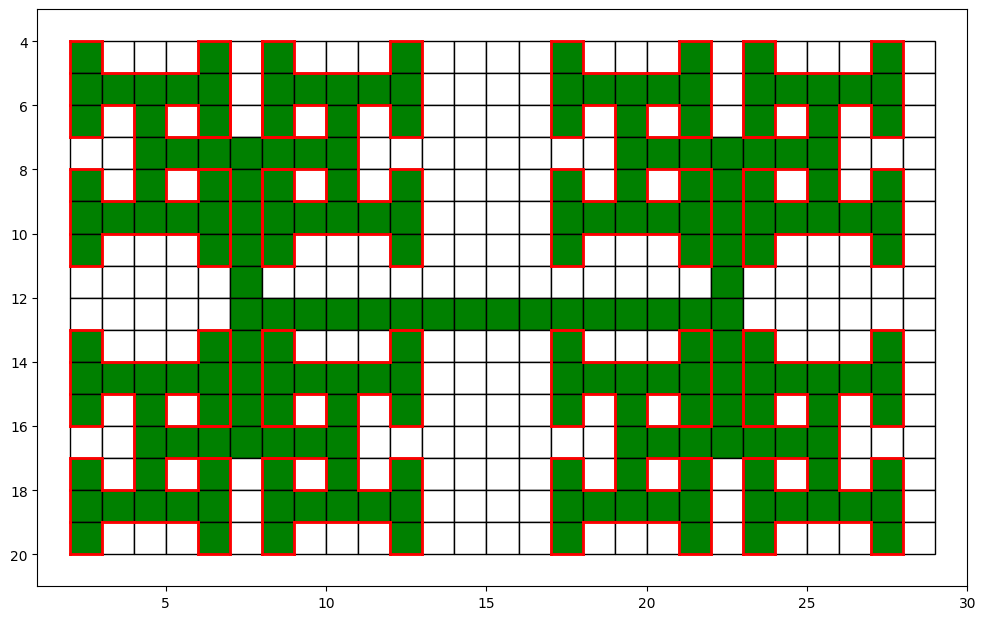

In [66]:
def visualize_full_grid(tiles_df, export=False):
    """
    Visualize the entire grid with green color for tiles in the graph and red borders for all tiles.

    Args:
    - tiles_df (pd.DataFrame): DataFrame containing tile information with 'coordinates', 'is_graph', and 'borders' columns.
    """
    fig, ax = plt.subplots()
    for idx, row in tiles_df.iterrows():
        x, y = row['coordinates']
        color = 'green' if row['is_graph'] else 'white'
        rect = plt.Rectangle((x, y), 1, 1, facecolor=color, edgecolor='black')
        ax.add_patch(rect)
        
        # Draw red borders for all tiles
        if row['borders'][0]:  # Top border
            ax.plot([x, x + 1], [y, y], color='red', linewidth=2)
        if row['borders'][1]:  # Right border
            ax.plot([x + 1, x + 1], [y, y + 1], color='red', linewidth=2)
        if row['borders'][2]:  # Bottom border
            ax.plot([x, x + 1], [y + 1, y + 1], color='red', linewidth=2)
        if row['borders'][3]:  # Left border
            ax.plot([x, x], [y, y + 1], color='red', linewidth=2)
    
    ax.set_xlim(tiles_df['coordinates'].apply(lambda x: x[0]).min() - 1, tiles_df['coordinates'].apply(lambda x: x[0]).max() + 2)
    ax.set_ylim(tiles_df['coordinates'].apply(lambda x: x[1]).min() - 1, tiles_df['coordinates'].apply(lambda x: x[1]).max() + 2)
    ax.set_aspect('equal')
    # Set the plot size to be larger
    fig.set_size_inches(12, 8)
    plt.gca().invert_yaxis()
    if export:
        plt.savefig('/var/home/almogmeir/Documents/M.Sc/Project/Input/full_grid.png')
    plt.show()


visualize_full_grid(test_tiles, export=True)

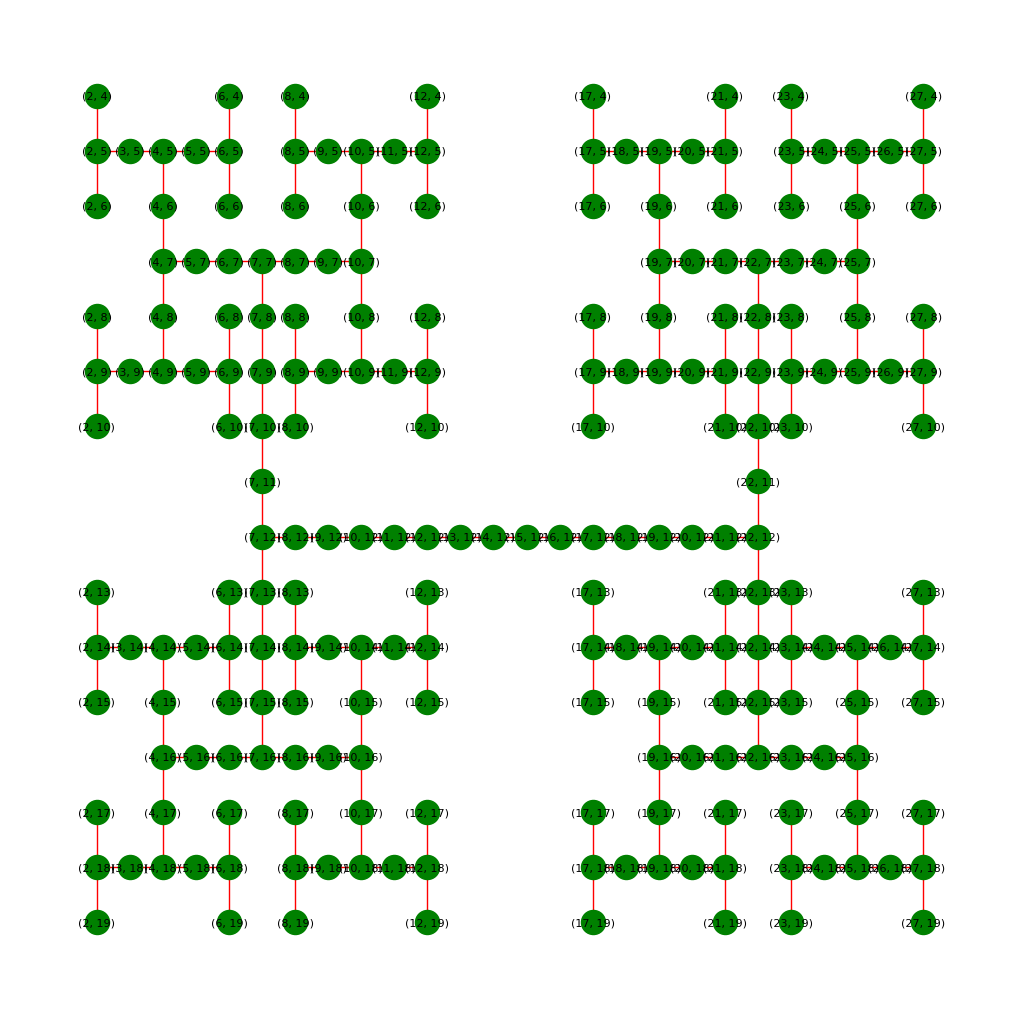

In [67]:
import networkx as nx

def create_graph_from_tiles(tiles_df):
    """
    Create a graph from the tiles_df based on the neighbors of each tile, taking into account the borders.
    Nodes are created for tiles that are endpoints or junctions, and tiles that have neighbors only to the left and right or up and down are considered part of the edge between nodes.

    Args:
    - tiles_df (pd.DataFrame): DataFrame containing tile information with 'coordinates', 'is_graph', and 'borders' columns.

    Returns:
    - G (networkx.Graph): Graph representing the tiles and their neighbors.
    """
    G = nx.Graph()

    # Define the directions for neighbors
    directions = {
        'top': (0, -1),
        'right': (1, 0),
        'bottom': (0, 1),
        'left': (-1, 0)
    }

    # Helper function to get neighbors
    def get_neighbors(x, y, borders):
        neighbors = []
        for i, (dx, dy) in enumerate(directions.values()):
            if not borders[i]:  # If there is no border in this direction
                neighbor_coord = (x + dx, y + dy)
                neighbor_idx = tiles_df[tiles_df['coordinates'] == neighbor_coord].index
                if not neighbor_idx.empty and tiles_df.at[neighbor_idx[0], 'is_graph']:
                    neighbors.append((neighbor_coord, i))
        return neighbors

    # Add nodes and edges to the graph
    for idx, row in tiles_df.iterrows():
        if row['is_graph']:
            x, y = row['coordinates']
            borders = row['borders']
            neighbors = get_neighbors(x, y, borders)

            G.add_node((x, y))

    # Add edges to the graph
    for idx, row in tiles_df.iterrows():
        if row['is_graph']:
            x, y = row['coordinates']
            borders = row['borders']
            neighbors = get_neighbors(x, y, borders)

            if len(neighbors) == 2 and neighbors[0][1] % 2 != neighbors[1][1] % 2:  # Part of a straight line
                continue

            for neighbor, _ in neighbors:
                if G.has_node(neighbor):
                    G.add_edge((x, y), neighbor)

    return G

tiles_G = create_graph_from_tiles(test_tiles)

def visualize_graph(G):
    """
    Visualize the graph with nodes and edges.

    Args:
    - G (networkx.Graph): Graph representing the tiles and their neighbors.
    """
    pos = {node: node for node in G.nodes()}
    plt.figure(figsize=(10, 10))
    nx.draw(G, pos, with_labels=True, node_color='green', edge_color='red', node_size=300, font_size=8)
    plt.gca().invert_yaxis()
    plt.show()

visualize_graph(tiles_G)

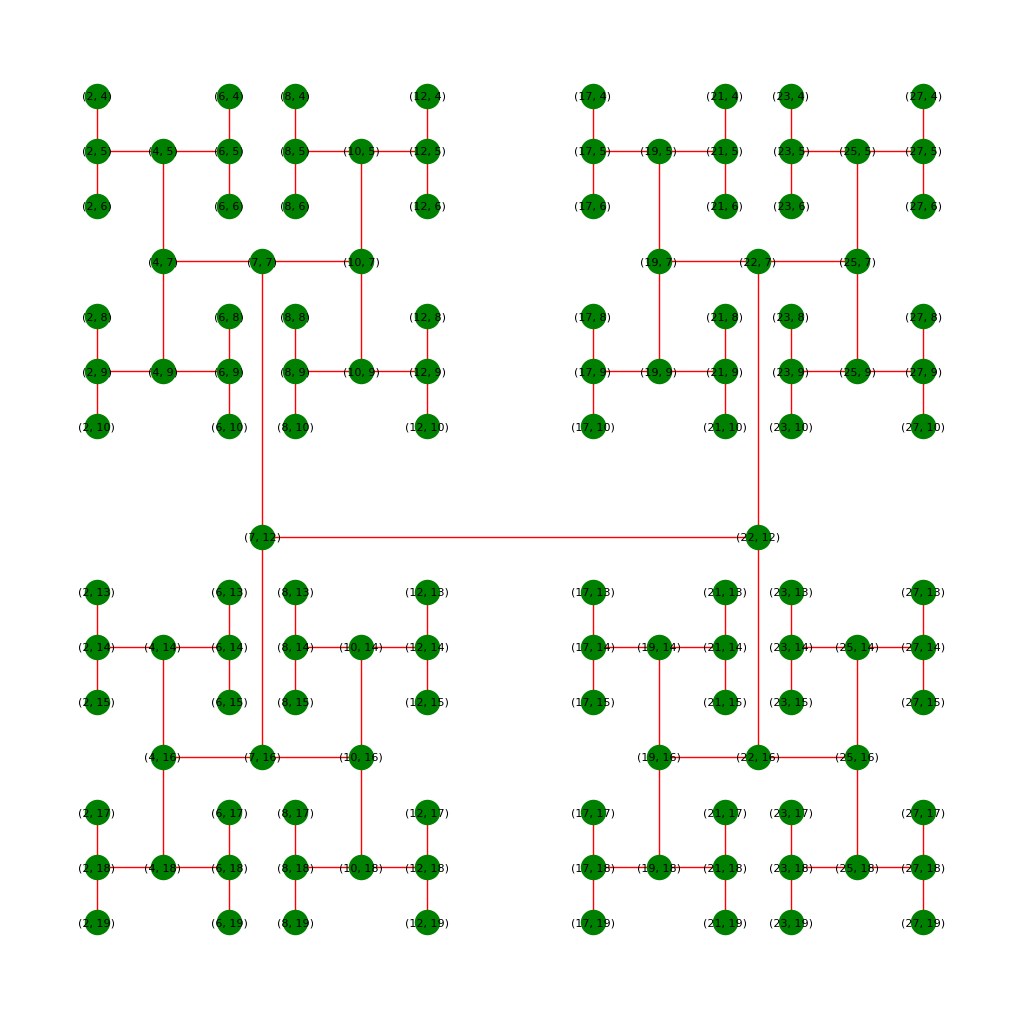

In [68]:
def simplify_graph(G):
    """
    Simplify the graph by removing nodes that have exactly two edges that go to nodes on the same straight line,
    and connecting their neighbor nodes directly. This is done row by row and then column by column.

    Args:
    - G (networkx.Graph): Graph representing the tiles and their neighbors.

    Returns:
    - G (networkx.Graph): Simplified graph.
    """
    def simplify_row(G):
        nodes_to_remove = []
        for y in sorted(set(node[1] for node in G.nodes())):  # Iterate over each row
            row_nodes = sorted([node for node in G.nodes() if node[1] == y], key=lambda node: node[0])
            for i in range(1, len(row_nodes) - 1):
                node = row_nodes[i]
                neighbors = list(G.neighbors(node))
                if len(neighbors) == 2:
                    (x1, y1), (x2, y2) = neighbors
                    if y1 == y and y2 == y:  # Check if neighbors are on the same row
                        # Add an edge between the two neighbors
                        G.add_edge(neighbors[0], neighbors[1])
                        # Mark the current node for removal
                        nodes_to_remove.append(node)
        # Remove the marked nodes
        G.remove_nodes_from(nodes_to_remove)
        return nodes_to_remove

    def simplify_column(G):
        nodes_to_remove = []
        for x in sorted(set(node[0] for node in G.nodes())):  # Iterate over each column
            column_nodes = sorted([node for node in G.nodes() if node[0] == x], key=lambda node: node[1])
            for i in range(1, len(column_nodes) - 1):
                node = column_nodes[i]
                neighbors = list(G.neighbors(node))
                if len(neighbors) == 2:
                    (x1, y1), (x2, y2) = neighbors
                    if x1 == x and x2 == x:  # Check if neighbors are on the same column
                        # Add an edge between the two neighbors
                        G.add_edge(neighbors[0], neighbors[1])
                        # Mark the current node for removal
                        nodes_to_remove.append(node)
        # Remove the marked nodes
        G.remove_nodes_from(nodes_to_remove)
        return nodes_to_remove

    # Simplify the graph row by row and column by column until no more nodes can be removed
    G = G.copy()
    edges = []
    while True:
        r = simplify_row(G)
        c = simplify_column(G)
        # Append to edges all the edges that were removed
        edges.extend([(r[i]) for i in range(len(r))])
        edges.extend([(c[i]) for i in range(len(c))])
        if len(r) == 0 and len(c) == 0:
            break
    edges_G = nx.Graph()
    edges_G.add_nodes_from(edges)

    return G, edges_G

G, edges_G = simplify_graph(tiles_G)
visualize_graph(G)

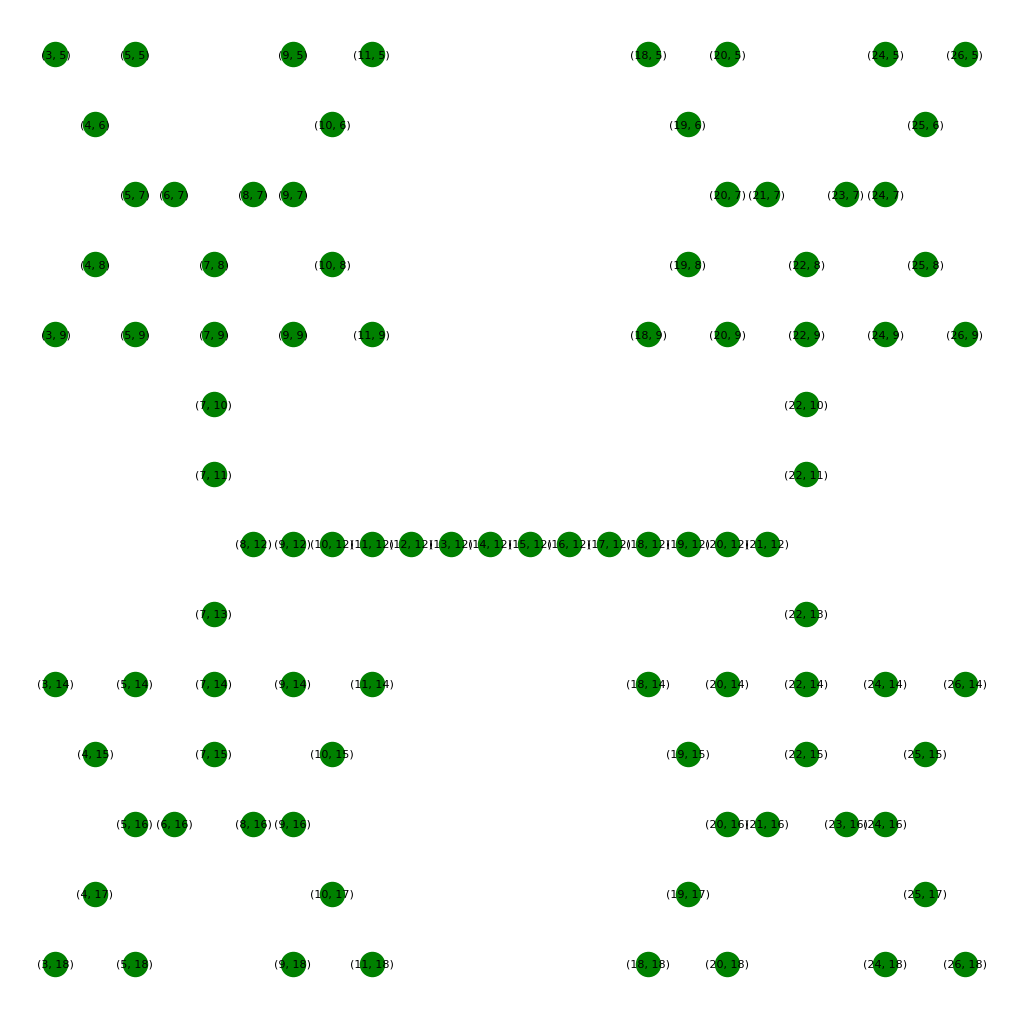

In [69]:
visualize_graph(edges_G)

In [24]:
!pip install pydot

Defaulting to user installation because normal site-packages is not writeable


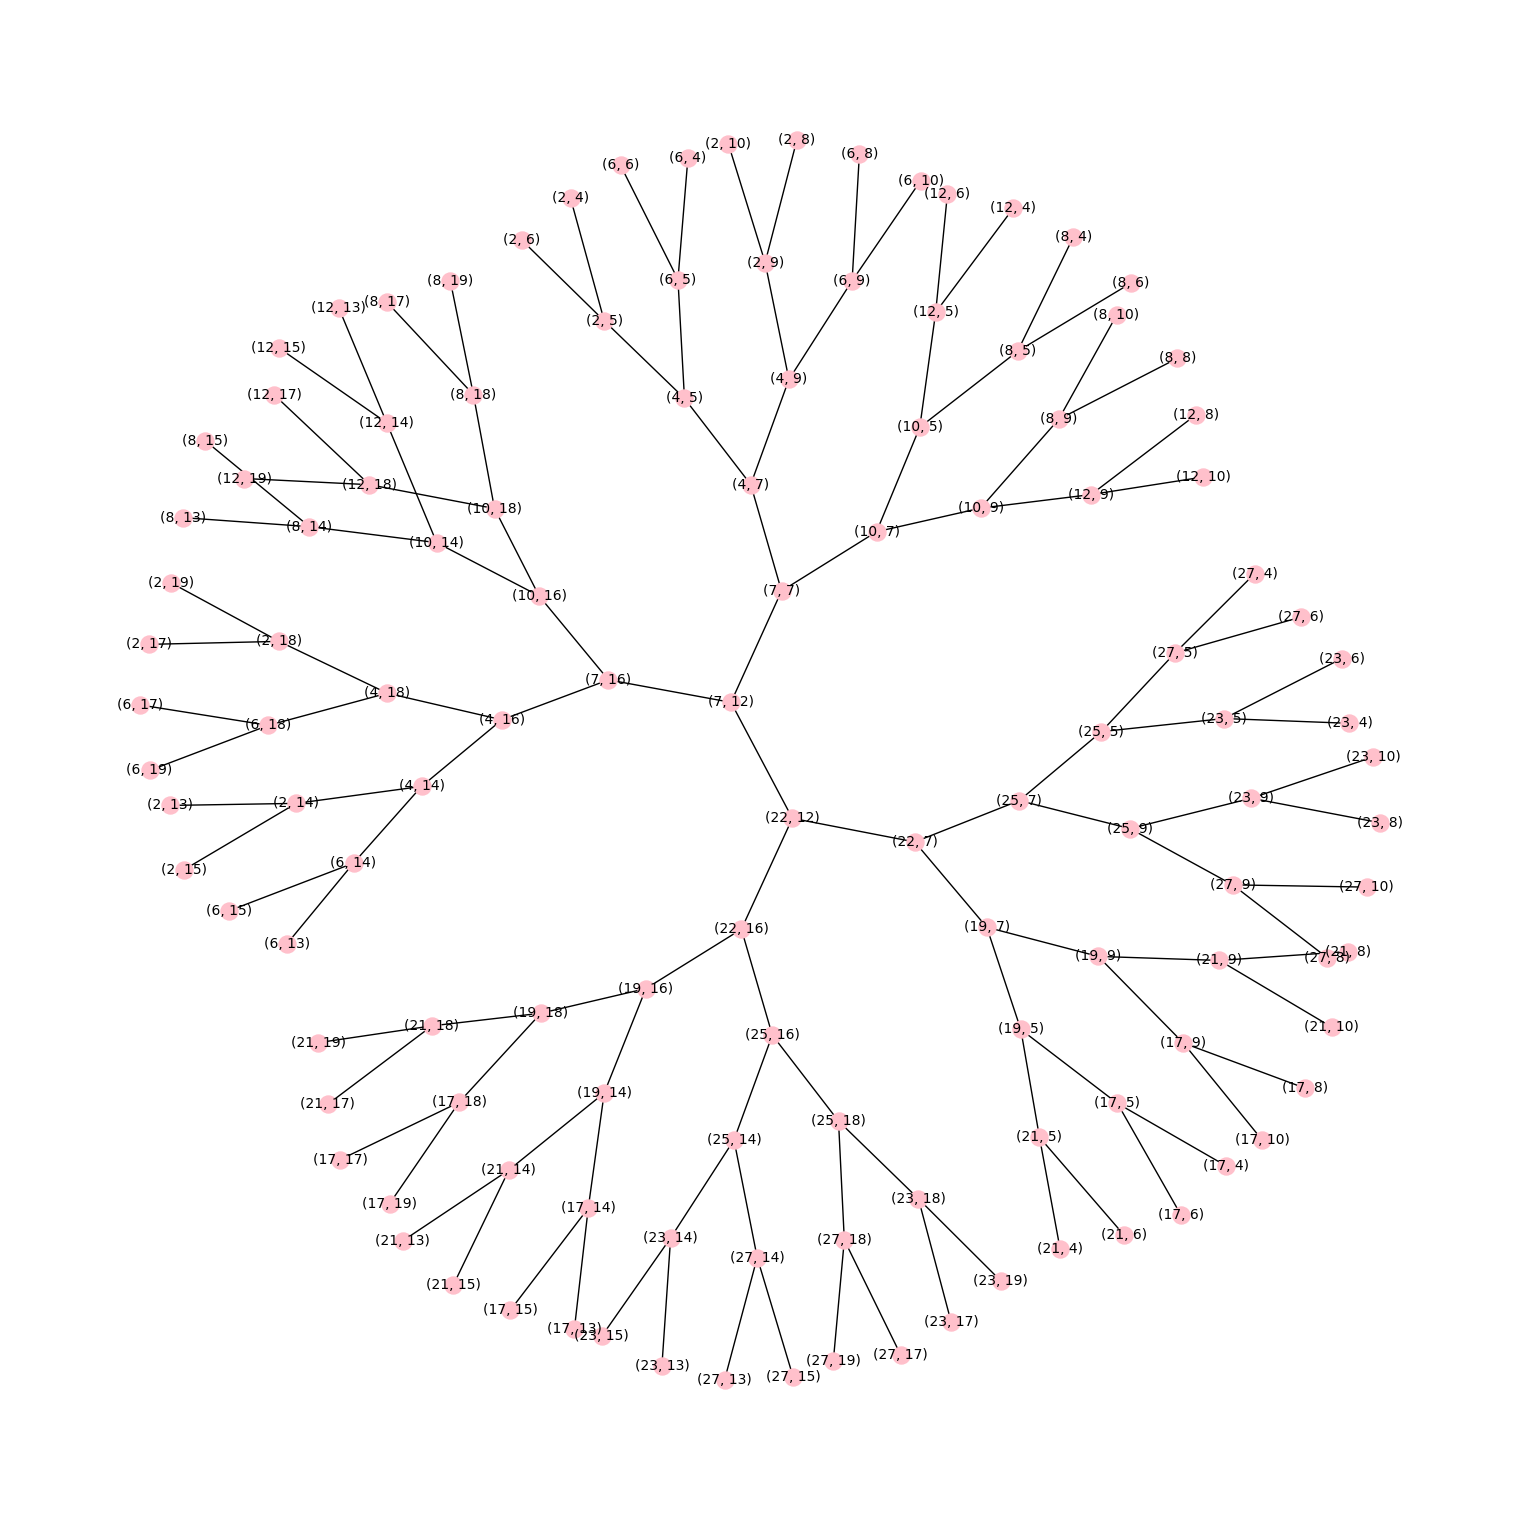

In [70]:
import pydot
from networkx.drawing.nx_pydot import graphviz_layout

# root_node = (14,7)
root_node = (7,12)
plt.figure(figsize=(15,15))
pos = graphviz_layout(G, prog="neato", root=root_node)
nx.draw(G, pos, with_labels=True, node_size=150, font_size=10, node_color='pink')
plt.show()

In [71]:
# maze1
# root_node = (14,7)
# grid_size = (24,16)
# grid_start = (3,4)

# maze2
root_node = (7,12)
grid_size = (27,16)
grid_start = (2,4)


tiles_dict = {(x + grid_start[0], y + grid_start[1]): y * grid_size[0] + x for y in range(grid_size[1]) for x in range(grid_size[0])}  
print(tiles_dict)

{(2, 4): 0, (3, 4): 1, (4, 4): 2, (5, 4): 3, (6, 4): 4, (7, 4): 5, (8, 4): 6, (9, 4): 7, (10, 4): 8, (11, 4): 9, (12, 4): 10, (13, 4): 11, (14, 4): 12, (15, 4): 13, (16, 4): 14, (17, 4): 15, (18, 4): 16, (19, 4): 17, (20, 4): 18, (21, 4): 19, (22, 4): 20, (23, 4): 21, (24, 4): 22, (25, 4): 23, (26, 4): 24, (27, 4): 25, (28, 4): 26, (2, 5): 27, (3, 5): 28, (4, 5): 29, (5, 5): 30, (6, 5): 31, (7, 5): 32, (8, 5): 33, (9, 5): 34, (10, 5): 35, (11, 5): 36, (12, 5): 37, (13, 5): 38, (14, 5): 39, (15, 5): 40, (16, 5): 41, (17, 5): 42, (18, 5): 43, (19, 5): 44, (20, 5): 45, (21, 5): 46, (22, 5): 47, (23, 5): 48, (24, 5): 49, (25, 5): 50, (26, 5): 51, (27, 5): 52, (28, 5): 53, (2, 6): 54, (3, 6): 55, (4, 6): 56, (5, 6): 57, (6, 6): 58, (7, 6): 59, (8, 6): 60, (9, 6): 61, (10, 6): 62, (11, 6): 63, (12, 6): 64, (13, 6): 65, (14, 6): 66, (15, 6): 67, (16, 6): 68, (17, 6): 69, (18, 6): 70, (19, 6): 71, (20, 6): 72, (21, 6): 73, (22, 6): 74, (23, 6): 75, (24, 6): 76, (25, 6): 77, (26, 6): 78, (27, 6

In [28]:
# def create_graph_with_pos(G, root_node):
#     new_G = nx.Graph()
#     pos = {}
    
#     def traverse(node, level=0, label_id=0, parent=None):
#         if node not in pos:
#             pos[node] = (level, label_id)
#             new_G.add_node(tiles_dict[node], pos=(label_id, level))
#             if parent is not None:
#                 new_G.add_edge(parent, node)
        
#         children = [n for n in G.neighbors(node) if n != parent]
#         for i, child in enumerate(children):
#             traverse(child, level + 1, i, node)
    
#     traverse(root_node)
#     return new_G

# G = create_graph_with_pos(G, root_node)
# # visualize_graph(G)

In [72]:
tiles_dict[(2,4)]

0

In [28]:
nx.get_node_attributes(G, 'pos')

{}

In [31]:
import pickle
with open('/var/home/almogmeir/Documents/M.Sc/Project/maze2.gpickle', 'wb') as f:
    pickle.dump(G, f, pickle.HIGHEST_PROTOCOL)

In [32]:
with open('/var/home/almogmeir/Documents/M.Sc/Project/maze2.gpickle', 'rb') as f:
    read_G = pickle.load(f)

nx.get_node_attributes(read_G, 'pos')

{}

In [33]:
nx.get_node_attributes(read_G, 'pos')[518]

KeyError: 518

In [73]:
tiles_dict[(14,11)]

201

In [74]:
max_grid_row, max_grid_col = np.array((16, 27)) * 32
origin_row, origin_col = eval(str((147, 182)))
origin_row

147

In [75]:
from collections import deque

def numerate_nodes(G, root_node, grid_size, grid_start):
    tiles_dict = {(x + grid_start[0], y + grid_start[1]): y * grid_size[0] + x for y in range(grid_size[1]) for x in range(grid_size[0])}    
    return tiles_dict

def create_dict_nodes(G, root_node, tiles_dict):
    """
    Traverse a tree graph and create a dictionary where each key is a tile number
    and the value is an integer based on the level of the tree.

    Args:
    - G (networkx.Graph): Tree graph to traverse.
    - root_node (tuple): Coordinates of the root node.
    - grid_size (tuple): Size of the grid (width, height).
    - grid_start (tuple): Coordinates of the first tile in the grid.

    Returns:
    - dict: Dictionary with tile numbers as keys and level integers as values.
    """

    # Initialize the dictionary and the queue for BFS
    nodes_dict = {}
    queue = deque([(root_node, 0)])  # (node, level)
    # Map the tiles coordinates to tile numbers row by row starting with 0, from the top left
    level_counters = {}  # To keep track of the index for each level


    while queue:
        node, level = queue.popleft()
        x, y = node[0], node[1]
        tile_number = tiles_dict[(x, y)]
        
        # Initialize the counter for this level if not already done
        if level not in level_counters:
            level_counters[level] = 0

        # Assign the unique level number to the tile number
        if level_counters[level] < 10:
            unique_level_number = level * 10 + level_counters[level]
        else:
            unique_level_number = level * 100 + level_counters[level]
        nodes_dict[tile_number] = unique_level_number

        # Increment the counter for this level
        level_counters[level] += 1

        # print(f"Node: {node}, Level: {unique_level_number}, Tile Number: {tile_number}")

        # Add children to the queue with incremented level
        for neighbor in G.neighbors(node):
            n_x = neighbor[0]
            n_y = neighbor[1]
            if tiles_dict[(n_x, n_y)] not in nodes_dict:
                queue.append((neighbor, level + 1))

    return nodes_dict

# Example usage:
# G is the graph, root_node is the root node, grid_size is (42, 42), grid_start is (0, 0)
tiles_dict = numerate_nodes(G, root_node, grid_size, grid_start)
nodes_dict = create_dict_nodes(G, root_node, tiles_dict)
print(nodes_dict)

{221: 0, 329: 10, 86: 11, 236: 12, 326: 20, 332: 21, 83: 22, 89: 23, 344: 24, 101: 25, 272: 30, 380: 31, 278: 32, 386: 33, 29: 34, 137: 35, 35: 36, 143: 37, 341: 38, 347: 39, 98: 310, 104: 311, 270: 40, 274: 41, 378: 42, 382: 43, 276: 44, 280: 45, 384: 46, 388: 47, 27: 48, 31: 49, 135: 410, 139: 411, 33: 412, 37: 413, 141: 414, 145: 415, 287: 416, 395: 417, 293: 418, 401: 419, 44: 420, 152: 421, 50: 422, 158: 423, 243: 50, 297: 51, 247: 52, 301: 53, 351: 54, 405: 55, 355: 56, 409: 57, 249: 58, 303: 59, 253: 510, 307: 511, 357: 512, 411: 513, 361: 514, 415: 515, 0: 516, 54: 517, 4: 518, 58: 519, 108: 520, 162: 521, 112: 522, 166: 523, 6: 524, 60: 525, 10: 526, 64: 527, 114: 528, 168: 529, 118: 530, 172: 531, 285: 532, 289: 533, 393: 534, 397: 535, 291: 536, 295: 537, 399: 538, 403: 539, 42: 540, 46: 541, 150: 542, 154: 543, 48: 544, 52: 545, 156: 546, 160: 547, 258: 60, 312: 61, 262: 62, 316: 63, 366: 64, 420: 65, 370: 66, 424: 67, 264: 68, 318: 69, 268: 610, 322: 611, 372: 612, 426: 61

In [60]:
%history -g

 2/1:
!pip install opencv-contrib-python
!pip install scikit-learn networkx matplotlib
import cv2
 2/2:
import numpy as np
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from google.colab.patches import cv2_imshow
from skimage.morphology import skeletonize
from scipy.ndimage import rotate
 2/3:
!pip install -U scikit-image
!pip install -U numpy
!pip install -U scipy
!pip install -U matplotlib
!pip install -U networkx
!pip install -U scikit-learn
!pip install -U pandas
 2/4:
import numpy as np
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from google.colab.patches import cv2_imshow
from skimage.morphology import skeletonize
from scipy.ndimage import rotate
 2/5:
import numpy as np
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from skimage.morphology import skeletonize
from scipy.ndimage import rotate
 

In [76]:
nodes_dict[83]

22

In [77]:
# Get number of leaf nodes in G
leaf_nodes = [node for node in G.nodes() if G.degree(node) == 1]
len(leaf_nodes)

64

In [78]:
def create_full_dict(nodes_dict, G, tiles_G, tiles_dict):
    """
    Create a dictionary that includes all the tiles that are edges.

    Args:
    - nodes_dict (dict): Dictionary with tile numbers as keys and node information as values.
    - G (networkx.Graph): Graph representing the tiles and their neighbors.
    - tiles_G (networkx.Graph): Graph representing the edges.
    - tiles_dict (dict): Dictionary mapping tile coordinates to tile numbers.

    Returns:
    - dict: Updated dictionary with edge information.
    """
    full_dict = nodes_dict.copy()

    def traverse_to_find_two_nodes(start_node, visited):
        """
        Traverse the neighbors until two node tiles (which exist in G) are found.

        Args:
        - start_node (tuple): The starting node for traversal.
        - visited (set): Set of visited nodes to avoid cycles.

        Returns:
        - tuple: The two node tiles found in G.
        """
        queue = deque([start_node])
        found_nodes = []
        while queue and len(found_nodes) < 2:
            node = queue.popleft()
            if node in G.nodes() and node not in found_nodes:
                found_nodes.append(node)
            visited.add(node)
            for neighbor in tiles_G.neighbors(node):
                if neighbor not in visited:
                    queue.append(neighbor)
        return tuple(found_nodes) if len(found_nodes) == 2 else None

    for edge_node in tiles_G.nodes():
        if edge_node in G.nodes():
            x, y = edge_node
            tile_number = tiles_dict[(x, y)]
            neighbors = list(tiles_G.neighbors(edge_node))
            found_node = False
            for neighbor in neighbors:
                if neighbor in G.nodes():
                    neighbor_tile_number = tiles_dict[neighbor]
                    tile_level = nodes_dict[tile_number]
                    neighbor_level = nodes_dict[neighbor_tile_number]
                    sorted_tup = tuple(sorted((tile_level, neighbor_level)))
                    full_dict[tile_number] = frozenset([full_dict[tile_number], sorted_tup])
                    found_node = True
                    break
        else:
            visited = set()
            node_tiles = traverse_to_find_two_nodes(edge_node, visited)
            if node_tiles:
                tile1_level = nodes_dict[tiles_dict[node_tiles[0]]]
                tile2_level = nodes_dict[tiles_dict[node_tiles[1]]]
                node_tile_numbers = tuple(sorted((tile1_level, tile2_level)))
                x, y = edge_node
                tile_number = tiles_dict[(x, y)]
                full_dict[tile_number] = node_tile_numbers

    return full_dict

# Example usage:
# nodes_dict is the dictionary with node information
# G is the graph, edges_G is the edges graph, tiles_dict is the dictionary mapping tile coordinates to tile numbers
final_dict = create_full_dict(nodes_dict, G, tiles_G, tiles_dict)
print(final_dict)

{221: 0, 329: 10, 86: 11, 236: 12, 326: 20, 332: 21, 83: 22, 89: 23, 344: 24, 101: 25, 272: 30, 380: 31, 278: 32, 386: 33, 29: 34, 137: 35, 35: 36, 143: 37, 341: 38, 347: 39, 98: 310, 104: 311, 270: frozenset({40, (40, 50)}), 274: frozenset({41, (41, 52)}), 378: frozenset({(42, 54), 42}), 382: frozenset({43, (43, 56)}), 276: frozenset({(44, 58), 44}), 280: frozenset({(45, 510), 45}), 384: frozenset({46, (46, 512)}), 388: frozenset({(47, 514), 47}), 27: frozenset({48, (48, 516)}), 31: frozenset({(49, 518), 49}), 135: frozenset({(410, 520), 410}), 139: frozenset({411, (411, 522)}), 33: frozenset({412, (412, 524)}), 37: frozenset({(413, 526), 413}), 141: frozenset({(414, 528), 414}), 145: frozenset({(415, 530), 415}), 287: 416, 395: 417, 293: 418, 401: 419, 44: 420, 152: 421, 50: 422, 158: 423, 243: frozenset({50, (40, 50)}), 297: frozenset({51, (40, 51)}), 247: frozenset({(41, 52), 52}), 301: frozenset({(41, 53), 53}), 351: frozenset({(42, 54), 54}), 405: frozenset({(42, 55), 55}), 355: 

# Add graph position to the raw pkl data from NaviGraph

In [34]:
%pip install ruamel.yaml

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [141]:
import pickle

with open('/var/home/almogmeir/Documents/M.Sc/Project/DLC/01_23_2025_13NC_rewardSize-01232025170447-0000/01_23_2025_13NC_rewardSize-01232025170447-0000_updated_raw.pkl', 'rb') as f:
    data_full = pickle.load(f)

# /var/home/almogmeir/Documents/M.Sc/Project/MazeMaster-dev/outputs/2025-01-27/13-31-53/01_16_2025_rewardsize_17NC-01162025152516-0000_raw.pkl
with open('/var/home/almogmeir/Documents/M.Sc/Project/DLC/01_23_2025_13NC_rewardSize-01232025170447-0000/01_23_2025_13NC_rewardSize-01232025170447-0000_raw.pkl', 'rb') as f:
    data_before = pickle.load(f)

# Load the dlc data from csv to df
# dlc_raw = pd.read_csv('/var/home/almogmeir/Documents/M.Sc/Project/MazeMaster-dev/outputs/2025-01-27/13-31-53/01_16_2025_rewardsize_17NC-01162025152516-0000DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.csv')

# h5_file = pd.read_hdf('/var/home/almogmeir/Documents/M.Sc/Project/01_16_2025_rewardsize_17NC-01162025152516-0000.h5')

In [41]:
# Read the graph using adjlist
# G = nx.read_adjlist('/var/home/almogmeir/Documents/M.Sc/Project/Mazes/maze2.adjlist')

In [142]:
# Find the first and last index where 'tree_position' is not null for at least 2 consecutive rows
first_valid_index = None
last_valid_index = None

for i in range(len(data_full) - 1):
    if pd.notnull(data_full.loc[i, 'tree_position']) and pd.notnull(data_full.loc[i + 1, 'tree_position']):
        first_valid_index = i
        break

for i in range(len(data_full) - 1, 0, -1):
    if pd.notnull(data_full.loc[i, 'tree_position']) and pd.notnull(data_full.loc[i - 1, 'tree_position']):
        last_valid_index = i
        break

# Calculate the number of rows to be removed from start and end
rows_removed_start = first_valid_index
rows_removed_end = len(data_full) - last_valid_index - 1

# Remove the rows
data = data_full.loc[first_valid_index:last_valid_index]

# Print the number of rows removed
print(f"Number of rows removed from start: {rows_removed_start}")
print(f"Number of rows removed from end: {rows_removed_end}")

Number of rows removed from start: 0
Number of rows removed from end: 0


In [143]:
data

coords,x,y,likelihood,tile_box,tile_id,tree_position
0,551.053162,820.800171,0.963719,"[502, 595, 31, 31]",388.0,"((47, 514), 47)"
1,550.746338,823.011230,0.949312,"[502, 595, 31, 31]",388.0,"((47, 514), 47)"
2,551.094788,825.726379,0.909568,"[502, 595, 31, 31]",388.0,"((47, 514), 47)"
3,550.287659,826.767578,0.909067,"[502, 595, 31, 31]",388.0,"((47, 514), 47)"
4,551.438599,830.332092,0.978875,"[502, 627, 31, 31]",415.0,"(515, (47, 515))"
...,...,...,...,...,...,...
99570,149.979324,633.626343,0.451042,"[182, 467, 31, 31]",270.0,"(40, (40, 50))"
99571,147.265808,632.973816,0.627250,"[182, 467, 31, 31]",270.0,"(40, (40, 50))"
99572,146.065842,633.263550,0.714764,"[182, 467, 31, 31]",270.0,"(40, (40, 50))"
99573,143.665802,634.119751,0.789346,"[182, 467, 31, 31]",270.0,"(40, (40, 50))"


In [144]:
data_before

coords,x,y,likelihood,tile_box,tile_id,tree_position
0,551.053162,820.800171,0.963719,"[502, 595, 31, 31]",388.0,"((47, 514), 47)"
1,550.746338,823.011230,0.949312,"[502, 595, 31, 31]",388.0,"((47, 514), 47)"
2,551.094788,825.726379,0.909568,"[502, 595, 31, 31]",388.0,"((47, 514), 47)"
3,550.287659,826.767578,0.909067,"[502, 595, 31, 31]",388.0,"((47, 514), 47)"
4,551.438599,830.332092,0.978875,"[502, 627, 31, 31]",415.0,"(515, (47, 515))"
...,...,...,...,...,...,...
99570,149.979324,633.626343,0.451042,"[182, 467, 31, 31]",270.0,"(40, (40, 50))"
99571,147.265808,632.973816,0.627250,"[182, 467, 31, 31]",270.0,"(40, (40, 50))"
99572,146.065842,633.263550,0.714764,"[182, 467, 31, 31]",270.0,"(40, (40, 50))"
99573,143.665802,634.119751,0.789346,"[182, 467, 31, 31]",270.0,"(40, (40, 50))"


In [11]:
dlc_raw
likelihood_columns = dlc_raw.loc[:, dlc_raw.iloc[1] == 'likelihood']
likelihood_columns

,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.2,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.5,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.8,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.11,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.14
0,nose,ear_R,ear_L,mid_body,tail_base
1,likelihood,likelihood,likelihood,likelihood,likelihood
2,0.301229327917099,0.2663849890232086,0.49790939688682556,0.7337660193443298,0.36483660340309143
3,0.31701916456222534,0.24024324119091034,0.47844529151916504,0.6524948477745056,0.34202373027801514
4,0.37913596630096436,0.25891390442848206,0.5189719796180725,0.6472910046577454,0.2594771385192871
...,...,...,...,...,...
100848,0.324106,0.242903,0.48381,0.981035,0.991836
100849,0.348444,0.279702,0.506236,0.983298,0.992491
100850,0.333846,0.282268,0.534847,0.982606,0.993141
100851,0.36344,0.241012,0.512872,0.982961,0.993115


In [15]:
# Convert the likelihood columns to float
likelihood_columns = likelihood_columns.astype(float)

# Filter rows where all likelihoods are less than 0.3
filtered_likelihoods = likelihood_columns[(likelihood_columns < 0.3).all(axis=1)]

filtered_likelihoods

,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.2,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.5,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.8,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.11,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.14
59873,0.069219,0.010230,0.011562,0.028733,0.253206
59876,0.039013,0.009428,0.009498,0.028411,0.192052
63465,0.124383,0.057852,0.015690,0.047153,0.257369
63467,0.030292,0.006883,0.006251,0.018166,0.118640
63468,0.058190,0.013595,0.013176,0.042998,0.270955
63470,0.024392,0.005061,0.003174,0.012131,0.090709
63483,0.168466,0.037038,0.044650,0.035466,0.233486
77935,0.248017,0.076136,0.212515,0.040482,0.255851
77941,0.136783,0.033689,0.038032,0.036856,0.215199
77945,0.110130,0.030582,0.032819,0.032327,0.214325


In [145]:
data['tile_id'] = data['tile_id'].fillna(0).astype(int)
data_before['tile_id'] = data_before['tile_id'].fillna(0).astype(int)

In [146]:
data[200:220]

coords,x,y,likelihood,tile_box,tile_id,tree_position
200,346.051483,708.050293,0.632076,"[342, 531, 31, 31]",329,10
201,345.018097,706.133789,0.700835,"[342, 531, 31, 31]",329,10
202,340.270966,704.587158,0.832530,"[342, 531, 31, 31]",329,10
203,336.655884,702.146362,0.968585,"[342, 499, 31, 31]",302,"(0, 10)"
204,336.659271,699.169128,0.957831,"[342, 499, 31, 31]",302,"(0, 10)"
205,335.973083,698.361084,0.948615,"[342, 499, 31, 31]",302,"(0, 10)"
206,336.965332,696.131165,0.886562,"[342, 499, 31, 31]",302,"(0, 10)"
207,338.446289,691.709045,0.906518,"[342, 499, 31, 31]",302,"(0, 10)"
208,339.304657,687.423340,0.899582,"[342, 499, 31, 31]",302,"(0, 10)"
209,344.413116,679.157959,0.579044,"[342, 499, 31, 31]",302,"(0, 10)"


In [147]:
# Show row in data_before where likelihood is nan
data_before[data_before['likelihood'].isna()]

coords,x,y,likelihood,tile_box,tile_id,tree_position
156,NaN,NaN,NaN,NaN,0,NaN
157,NaN,NaN,NaN,NaN,0,NaN
158,NaN,NaN,NaN,NaN,0,NaN
159,NaN,NaN,NaN,NaN,0,NaN
160,NaN,NaN,NaN,NaN,0,NaN
...,...,...,...,...,...,...
99502,NaN,NaN,NaN,NaN,0,NaN
99503,NaN,NaN,NaN,NaN,0,NaN
99504,NaN,NaN,NaN,NaN,0,NaN
99505,NaN,NaN,NaN,NaN,0,NaN


In [148]:
# Show row in data where likelihood is nan
data[data['likelihood'].isna()]

coords,x,y,likelihood,tile_box,tile_id,tree_position
546,NaN,NaN,NaN,NaN,0,NaN
547,NaN,NaN,NaN,NaN,0,NaN
551,NaN,NaN,NaN,NaN,0,NaN
552,NaN,NaN,NaN,NaN,0,NaN
561,NaN,NaN,NaN,NaN,0,NaN
...,...,...,...,...,...,...
94911,NaN,NaN,NaN,NaN,0,NaN
94918,NaN,NaN,NaN,NaN,0,NaN
94920,NaN,NaN,NaN,NaN,0,NaN
94924,NaN,NaN,NaN,NaN,0,NaN


In [105]:
tiles_dict

{(2, 4): 0,
 (3, 4): 1,
 (4, 4): 2,
 (5, 4): 3,
 (6, 4): 4,
 (7, 4): 5,
 (8, 4): 6,
 (9, 4): 7,
 (10, 4): 8,
 (11, 4): 9,
 (12, 4): 10,
 (13, 4): 11,
 (14, 4): 12,
 (15, 4): 13,
 (16, 4): 14,
 (17, 4): 15,
 (18, 4): 16,
 (19, 4): 17,
 (20, 4): 18,
 (21, 4): 19,
 (22, 4): 20,
 (23, 4): 21,
 (24, 4): 22,
 (25, 4): 23,
 (26, 4): 24,
 (27, 4): 25,
 (28, 4): 26,
 (2, 5): 27,
 (3, 5): 28,
 (4, 5): 29,
 (5, 5): 30,
 (6, 5): 31,
 (7, 5): 32,
 (8, 5): 33,
 (9, 5): 34,
 (10, 5): 35,
 (11, 5): 36,
 (12, 5): 37,
 (13, 5): 38,
 (14, 5): 39,
 (15, 5): 40,
 (16, 5): 41,
 (17, 5): 42,
 (18, 5): 43,
 (19, 5): 44,
 (20, 5): 45,
 (21, 5): 46,
 (22, 5): 47,
 (23, 5): 48,
 (24, 5): 49,
 (25, 5): 50,
 (26, 5): 51,
 (27, 5): 52,
 (28, 5): 53,
 (2, 6): 54,
 (3, 6): 55,
 (4, 6): 56,
 (5, 6): 57,
 (6, 6): 58,
 (7, 6): 59,
 (8, 6): 60,
 (9, 6): 61,
 (10, 6): 62,
 (11, 6): 63,
 (12, 6): 64,
 (13, 6): 65,
 (14, 6): 66,
 (15, 6): 67,
 (16, 6): 68,
 (17, 6): 69,
 (18, 6): 70,
 (19, 6): 71,
 (20, 6): 72,
 (21, 6): 73

In [421]:
# Get the key of a value in tiles_dict
key_list = list(tiles_dict.keys())
val_list = list(tiles_dict.values())
# position = val_list.index(data['tile_id'][0])
# position = val_list.index(24)
# key_list[position]
data['graph_node'] = data['tile_id'].apply(lambda x: key_list[val_list.index(x)] if x in val_list else None)
data_before['graph_node'] = data_before['tile_id'].apply(lambda x: key_list[val_list.index(x)] if x in val_list else None)
# data['tree_position'] = data['tile_id'].apply(lambda x: nodes_dict[x] if x in nodes_dict else None)

In [149]:
# Get rows where tile_id equals 241
tile_241_rows = data[data['tile_id'] == 241]

# Calculate the average likelihood for tile_id 241
avg_likelihood_241 = tile_241_rows['likelihood'].mean()

# Get rows where tile_id does not equal 241
other_rows = data[data['tile_id'] != 241]

# Calculate the average likelihood for all other rows
avg_likelihood_others = other_rows['likelihood'].mean()

print(f"Average likelihood for tile_id 241: {avg_likelihood_241}")
print(f"Average likelihood for all other rows: {avg_likelihood_others}")

Average likelihood for tile_id 241: 0.9420264512300491
Average likelihood for all other rows: 0.7541948782710491


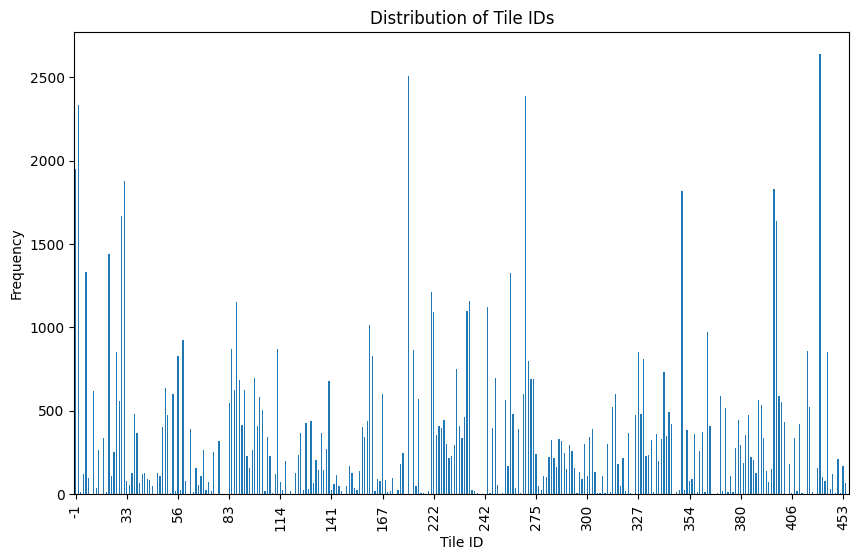

In [150]:
import matplotlib.pyplot as plt

# Plot the distribution of tile_ids
plt.figure(figsize=(10, 6))
ax = data['tile_id'].value_counts().sort_index().plot(kind='bar')
plt.xlabel('Tile ID')
plt.ylabel('Frequency')
plt.title('Distribution of Tile IDs')

# Set x-ticks to show only every other 20 tiles
xticks = ax.get_xticks()
ax.set_xticks(xticks[::20])
ax.set_xticklabels(data['tile_id'].value_counts().sort_index().index[::20])

plt.show()

In [151]:
# Sum the amount of every tile_id and show the top 20 most frequent
top_20_tile_ids = data['tile_id'].value_counts().head(20)
print(top_20_tile_ids)

tile_id
 426    2639
 187    2508
 271    2387
 0      2332
-1      1951
 31     1881
 399    1832
 351    1819
 30     1669
 400    1640
 25     1442
 4      1335
 262    1328
 221    1215
 236    1158
 86     1151
 243    1125
 235    1097
 222    1090
 159    1012
Name: count, dtype: int64


In [45]:
!pip install seaborn

Defaulting to user installation because normal site-packages is not writeable


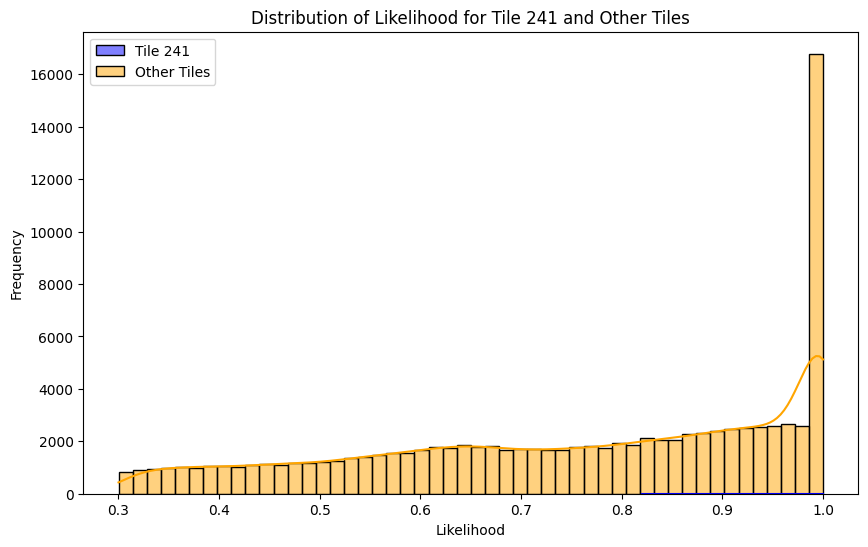

In [152]:
import seaborn as sns

import matplotlib.pyplot as plt

# Separate the likelihood of tile 241 and other tiles
tile_241_likelihood = tile_241_rows['likelihood']
other_likelihood = other_rows['likelihood']

# Plot the histogram
plt.figure(figsize=(10, 6))
sns.histplot(tile_241_likelihood, bins=50, kde=True, color='blue', label='Tile 241')
sns.histplot(other_likelihood, bins=50, kde=True, color='orange', label='Other Tiles')
plt.xlabel('Likelihood')
plt.ylabel('Frequency')
plt.title('Distribution of Likelihood for Tile 241 and Other Tiles')
plt.legend()
plt.show()

In [136]:
tile_241_rows

coords,x,y,likelihood,tile_box,tile_id,tree_position
119,1184.926880,538.100708,0.454482,"[982, 403, 31, 31]",241,None
120,1184.612915,538.217590,0.359297,"[982, 403, 31, 31]",241,None
193,1184.367920,538.038635,0.377835,"[982, 403, 31, 31]",241,None
194,1184.555542,537.908752,0.376225,"[982, 403, 31, 31]",241,None
239,1185.033813,538.643250,0.400705,"[982, 403, 31, 31]",241,None
...,...,...,...,...,...,...
100823,1184.639648,537.885681,0.394476,"[982, 403, 31, 31]",241,None
100825,1184.752686,538.331360,0.382946,"[982, 403, 31, 31]",241,None
100826,1184.050659,537.768860,0.310861,"[982, 403, 31, 31]",241,None
100827,1184.934082,538.436401,0.325103,"[982, 403, 31, 31]",241,None


In [153]:
data

coords,x,y,likelihood,tile_box,tile_id,tree_position
0,551.053162,820.800171,0.963719,"[502, 595, 31, 31]",388,"((47, 514), 47)"
1,550.746338,823.011230,0.949312,"[502, 595, 31, 31]",388,"((47, 514), 47)"
2,551.094788,825.726379,0.909568,"[502, 595, 31, 31]",388,"((47, 514), 47)"
3,550.287659,826.767578,0.909067,"[502, 595, 31, 31]",388,"((47, 514), 47)"
4,551.438599,830.332092,0.978875,"[502, 627, 31, 31]",415,"(515, (47, 515))"
...,...,...,...,...,...,...
99570,149.979324,633.626343,0.451042,"[182, 467, 31, 31]",270,"(40, (40, 50))"
99571,147.265808,632.973816,0.627250,"[182, 467, 31, 31]",270,"(40, (40, 50))"
99572,146.065842,633.263550,0.714764,"[182, 467, 31, 31]",270,"(40, (40, 50))"
99573,143.665802,634.119751,0.789346,"[182, 467, 31, 31]",270,"(40, (40, 50))"


In [61]:
dlc_raw

,scorer,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.1,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.2,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.3,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.4,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.5,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.6,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.7,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.8,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.9,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.10,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.11,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.12,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.13,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.14
0,bodyparts,nose,nose,nose,ear_R,ear_R,ear_R,ear_L,ear_L,ear_L,mid_body,mid_body,mid_body,tail_base,tail_base,tail_base
1,coords,x,y,likelihood,x,y,likelihood,x,y,likelihood,x,y,likelihood,x,y,likelihood
2,0,1185.16015625,538.5875244140625,0.301229327917099,1176.8519287109375,536.3508911132812,0.2663849890232086,1178.33740234375,532.390625,0.49790939688682556,1168.9871826171875,532.7610473632812,0.7337660193443298,1158.6318359375,527.58154296875,0.36483660340309143
3,1,1185.62451171875,538.7958984375,0.31701916456222534,1177.17822265625,536.4553833007812,0.24024324119091034,1178.4354248046875,532.6073608398438,0.47844529151916504,1169.237060546875,532.9617919921875,0.6524948477745056,1159.558349609375,530.8524169921875,0.34202373027801514
4,2,1184.983642578125,538.5599365234375,0.37913596630096436,1176.4970703125,536.8154907226562,0.25891390442848206,1177.749755859375,532.508056640625,0.5189719796180725,1169.224609375,532.7659912109375,0.6472910046577454,1159.7332763671875,530.74755859375,0.2594771385192871
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100848,100846,1184.224365,537.869141,0.324106,1161.398682,424.797394,0.242903,1177.327881,532.284668,0.48381,1153.382324,404.956329,0.981035,1134.431274,392.918152,0.991836
100849,100847,1184.558838,538.006897,0.348444,1161.256226,424.281067,0.279702,1177.287598,532.323853,0.506236,1153.304443,404.921539,0.983298,1134.522339,392.664276,0.992491
100850,100848,1184.719849,538.0354,0.333846,1161.000122,424.264923,0.282268,1177.296143,532.494934,0.534847,1153.317505,405.013428,0.982606,1134.577026,392.577759,0.993141
100851,100849,1184.665649,537.941528,0.36344,1160.645142,422.206757,0.241012,1176.740967,532.460144,0.512872,1153.009033,404.140686,0.982961,1134.431152,392.15329,0.993115


In [62]:
# Get the column where the first row equals 'ear_R' and the second row equals 'likelihood'
ear_R_likelihood_col = dlc_raw.loc[:, (dlc_raw.iloc[0] == 'ear_R') & (dlc_raw.iloc[1] == 'likelihood')]

# Display the column
ear_R_likelihood_col

,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.5
0,ear_R
1,likelihood
2,0.2663849890232086
3,0.24024324119091034
4,0.25891390442848206
...,...
100848,0.242903
100849,0.279702
100850,0.282268
100851,0.241012


In [80]:
# Update column names for dlc_raw
new_columns = [dlc_raw.columns[0]]  # Keep the first column name as is
for col in dlc_raw.columns[1:]:
    new_name = f"{dlc_raw[col][0]}_{dlc_raw[col][1]}"
    new_columns.append(new_name)

dlc_raw.columns = new_columns

In [81]:
# Remove the first 2 rows of dlc_raw
dlc_raw = dlc_raw[2:]
# Reset the index
dlc_raw = dlc_raw.reset_index(drop=True)
# Drop scorer column
# dlc_raw = dlc_raw.drop(columns=['scorer'])

In [65]:
dlc_raw

,scorer,nose_x,nose_y,nose_likelihood,ear_R_x,ear_R_y,ear_R_likelihood,ear_L_x,ear_L_y,ear_L_likelihood,mid_body_x,mid_body_y,mid_body_likelihood,tail_base_x,tail_base_y,tail_base_likelihood
0,0,1185.16015625,538.5875244140625,0.301229327917099,1176.8519287109375,536.3508911132812,0.2663849890232086,1178.33740234375,532.390625,0.49790939688682556,1168.9871826171875,532.7610473632812,0.7337660193443298,1158.6318359375,527.58154296875,0.36483660340309143
1,1,1185.62451171875,538.7958984375,0.31701916456222534,1177.17822265625,536.4553833007812,0.24024324119091034,1178.4354248046875,532.6073608398438,0.47844529151916504,1169.237060546875,532.9617919921875,0.6524948477745056,1159.558349609375,530.8524169921875,0.34202373027801514
2,2,1184.983642578125,538.5599365234375,0.37913596630096436,1176.4970703125,536.8154907226562,0.25891390442848206,1177.749755859375,532.508056640625,0.5189719796180725,1169.224609375,532.7659912109375,0.6472910046577454,1159.7332763671875,530.74755859375,0.2594771385192871
3,3,1184.867919921875,538.3194580078125,0.36116260290145874,1173.995361328125,534.832763671875,0.28298717737197876,1177.7548828125,532.1370849609375,0.5368120670318604,1168.8505859375,532.7349853515625,0.7036356925964355,1158.633544921875,527.6341552734375,0.322151243686676
4,4,1184.941162109375,538.401123046875,0.38132303953170776,1176.4388427734375,536.9107055664062,0.2691255509853363,1177.82080078125,532.2265014648438,0.5656877160072327,1168.8602294921875,532.7415161132812,0.6033950448036194,1159.476806640625,530.9556274414062,0.275037944316864
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100846,100846,1184.224365,537.869141,0.324106,1161.398682,424.797394,0.242903,1177.327881,532.284668,0.48381,1153.382324,404.956329,0.981035,1134.431274,392.918152,0.991836
100847,100847,1184.558838,538.006897,0.348444,1161.256226,424.281067,0.279702,1177.287598,532.323853,0.506236,1153.304443,404.921539,0.983298,1134.522339,392.664276,0.992491
100848,100848,1184.719849,538.0354,0.333846,1161.000122,424.264923,0.282268,1177.296143,532.494934,0.534847,1153.317505,405.013428,0.982606,1134.577026,392.577759,0.993141
100849,100849,1184.665649,537.941528,0.36344,1160.645142,422.206757,0.241012,1176.740967,532.460144,0.512872,1153.009033,404.140686,0.982961,1134.431152,392.15329,0.993115


In [52]:
# Assuming the indices of both dataframes match
# Add the columns from dlc_raw to data
data['ear_R_likelihood'] = dlc_raw['ear_R_likelihood']
data['ear_L_likelihood'] = dlc_raw['ear_L_likelihood']
data['mid_body_likelihood'] = dlc_raw['mid_body_likelihood']
data['tail_base_likelihood'] = dlc_raw['tail_base_likelihood']

# Display the updated dataframe
data.head()

coords,x,y,likelihood,tile_box,tile_id,tree_position,graph_node,ear_R_likelihood,ear_L_likelihood,mid_body_likelihood,tail_base_likelihood
0,1185.160156,538.587524,0.301229,"[982, 403, 31, 31]",241,None,"(27, 12)",0.2663849890232086,0.49790939688682556,0.7337660193443298,0.36483660340309143
1,1185.624512,538.795898,0.317019,"[982, 403, 31, 31]",241,None,"(27, 12)",0.24024324119091034,0.47844529151916504,0.6524948477745056,0.34202373027801514
2,1184.983643,538.559937,0.379136,"[982, 403, 31, 31]",241,None,"(27, 12)",0.25891390442848206,0.5189719796180725,0.6472910046577454,0.2594771385192871
3,1184.867920,538.319458,0.361163,"[982, 403, 31, 31]",241,None,"(27, 12)",0.28298717737197876,0.5368120670318604,0.7036356925964355,0.322151243686676
4,1184.941162,538.401123,0.381323,"[982, 403, 31, 31]",241,None,"(27, 12)",0.2691255509853363,0.5656877160072327,0.6033950448036194,0.275037944316864


In [379]:
data['tile_id_diff'] = data['tile_id'].diff()
data_before['tile_id_diff'] = data_before['tile_id'].diff()
filtered_data_not_241 = data[(data['tile_id_diff'] > 28) & (data['tile_id'] != 241)]
filtered_data_not_241

coords,x,y,likelihood,tile_box,tile_id,tree_position,tile_id_diff,graph_node
207,365.824921,486.801208,0.644436,"[342, 339, 31, 31]",167,"(0, 11)",54.0,"(7, 10)"
215,372.627869,529.082947,0.801550,"[374, 371, 31, 31]",195,None,55.0,"(8, 11)"
218,382.751709,543.787476,0.952264,"[374, 403, 31, 31]",222,"(0, 10)",55.0,"(8, 12)"
262,381.296173,713.672607,0.787917,"[374, 531, 31, 31]",330,"(10, 21)",55.0,"(8, 16)"
278,390.827301,709.143372,0.860953,"[374, 531, 31, 31]",330,"(10, 21)",55.0,"(8, 16)"
...,...,...,...,...,...,...,...,...
100024,377.811066,530.974304,0.822701,"[374, 403, 31, 31]",222,"(0, 10)",55.0,"(8, 12)"
100037,376.152985,543.978516,0.954053,"[374, 403, 31, 31]",222,"(0, 10)",55.0,"(8, 12)"
100573,905.297656,709.145322,0.696367,"[758, 531, 31, 31]",342,"(24, 38)",101.0,"(20, 16)"
100574,783.255981,786.681519,0.414698,"[662, 595, 31, 31]",393,"((64, 534), 534)",51.0,"(17, 18)"


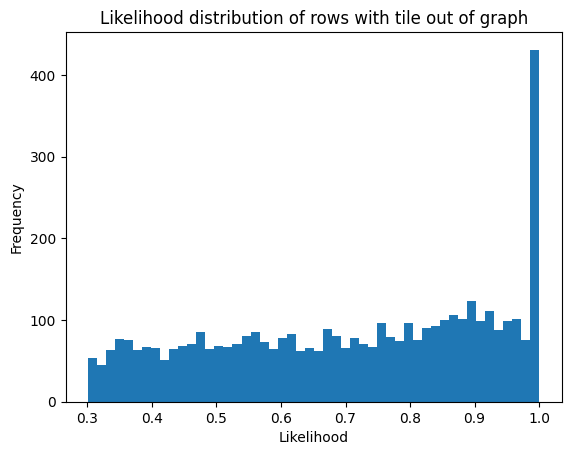

In [154]:
rows_with_none_tree_position = data[data['tree_position'].isnull() & (data['tile_id'] != 241) & data['likelihood'].notna()]
rows_with_none_tree_position_before = data_before[data_before['tree_position'].isnull() & (data_before['tile_id'] != 241) & data_before['likelihood'].notna()]

# Plot the likelihood ditribution of the rows with none tree position
plt.hist(rows_with_none_tree_position['likelihood'], bins=50)
plt.xlabel('Likelihood')
plt.ylabel('Frequency')
plt.title('Likelihood distribution of rows with tile out of graph')
plt.show()

In [155]:
rows_with_none_tree_position

coords,x,y,likelihood,tile_box,tile_id,tree_position
357,157.215332,246.406021,0.404935,"[214, 147, 31, 31]",1,None
422,168.209478,308.702518,0.660662,"[214, 211, 31, 31]",55,None
577,267.984456,325.951487,0.320815,"[278, 211, 31, 31]",57,None
626,276.037750,290.056976,1.000000,"[278, 211, 31, 31]",57,None
1154,1046.635085,297.584267,0.749956,"[886, 211, 31, 31]",76,None
...,...,...,...,...,...,...
98120,438.537231,454.936462,0.909394,"[406, 339, 31, 31]",169,None
98121,438.726044,455.510406,0.826785,"[406, 339, 31, 31]",169,None
98122,438.762146,455.082001,0.834782,"[406, 339, 31, 31]",169,None
98551,1140.692017,830.135071,0.400833,"[950, 627, 31, 31]",429,None


In [156]:
rows_with_none_tree_position_before

coords,x,y,likelihood,tile_box,tile_id,tree_position
357,157.215332,246.406021,0.404935,"[214, 147, 31, 31]",1,None
626,276.037750,290.056976,1.000000,"[278, 211, 31, 31]",57,None
1263,1054.127441,323.626099,0.350368,"[886, 211, 31, 31]",76,None
1596,1020.965027,784.053162,0.326864,"[886, 563, 31, 31]",373,None
1827,854.568420,701.890991,0.775836,"[758, 499, 31, 31]",315,None
...,...,...,...,...,...,...
98120,438.537231,454.936462,0.909394,"[406, 339, 31, 31]",169,None
98121,438.726044,455.510406,0.826785,"[406, 339, 31, 31]",169,None
98122,438.762146,455.082001,0.834782,"[406, 339, 31, 31]",169,None
98551,1140.692017,830.135071,0.400833,"[950, 627, 31, 31]",429,None


In [157]:
# Get number of rows with tile_id 241 in data and in data_before
rows_with_tile_241 = data[data['tile_id'] == 241]
rows_with_tile_241_before = data_before[data_before['tile_id'] == 241]

print('Number of rows with tile_id 241 in data:', len(rows_with_tile_241))
print('Number of rows with tile_id 241 in data_before:', len(rows_with_tile_241_before))

Number of rows with tile_id 241 in data: 4
Number of rows with tile_id 241 in data_before: 4


In [132]:
# Function to update tile_id based on previous and next rows' tile_ids
def update_tile_id(data):
    for idx in data[(data['tree_position'].isnull()) & (data['likelihood'].notna())].index:
        prev_tile_id = data.loc[idx - 1, 'tile_id'] if idx > 0 else None
        next_tile_id = data.loc[idx + 1, 'tile_id'] if idx < len(data) - 1 else None
        # prev_tree_pos = data.loc[idx - 1, 'tree_position'] if idx > 0 else None
        # next_tree_pos = data.loc[idx + 1, 'tree_position'] if idx < len(data) - 1 else None
        
        if prev_tile_id == next_tile_id:
            data.at[idx, 'tile_id'] = prev_tile_id
        elif prev_tile_id is not None and next_tile_id is not None:
            data.at[idx, 'tile_id'] = prev_tile_id if abs(data.loc[idx, 'tile_id'] - prev_tile_id) < abs(data.loc[idx, 'tile_id'] - next_tile_id) else next_tile_id
            new_tile_id = data.at[idx, 'tile_id']
        elif prev_tile_id is not None:
            data.at[idx, 'tile_id'] = prev_tile_id
        # elif next_tile_id is not None:
        else:
            data.at[idx, 'tile_id'] = next_tile_id
        # After updating the tile_id, update the tree_position as well
        if data.at[idx, 'tile_id'] in final_dict:
            data.at[idx, 'tree_position'] = final_dict[data.at[idx, 'tile_id']]

# Update the tile_id for the specified rows
update_tile_id(data)

# Verify the updates
# updated = data[(data['tree_position'].isnull()) & (data['likelihood'].notna())]
# updated[200:220]

In [158]:
data[200:220]

coords,x,y,likelihood,tile_box,tile_id,tree_position
200,346.051483,708.050293,0.632076,"[342, 531, 31, 31]",329,10
201,345.018097,706.133789,0.700835,"[342, 531, 31, 31]",329,10
202,340.270966,704.587158,0.832530,"[342, 531, 31, 31]",329,10
203,336.655884,702.146362,0.968585,"[342, 499, 31, 31]",302,"(0, 10)"
204,336.659271,699.169128,0.957831,"[342, 499, 31, 31]",302,"(0, 10)"
205,335.973083,698.361084,0.948615,"[342, 499, 31, 31]",302,"(0, 10)"
206,336.965332,696.131165,0.886562,"[342, 499, 31, 31]",302,"(0, 10)"
207,338.446289,691.709045,0.906518,"[342, 499, 31, 31]",302,"(0, 10)"
208,339.304657,687.423340,0.899582,"[342, 499, 31, 31]",302,"(0, 10)"
209,344.413116,679.157959,0.579044,"[342, 499, 31, 31]",302,"(0, 10)"


In [159]:
# Count the number of rows where likelihood is Nan
nan_likelihood_count = data['likelihood'].isnull().sum()
nan_likelihood_count_before = data_before['likelihood'].isnull().sum()

print(f'Number of rows where likelihood is Nan before update: {nan_likelihood_count_before}')
print(f'Number of rows where likelihood is Nan after update: {nan_likelihood_count}')

Number of rows where likelihood is Nan before update: 8371
Number of rows where likelihood is Nan after update: 1683


In [389]:
dlc_raw

,scorer,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.1,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.2,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.3,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.4,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.5,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.6,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.7,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.8,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.9,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.10,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.11,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.12,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.13,DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.14
0,bodyparts,nose,nose,nose,ear_R,ear_R,ear_R,ear_L,ear_L,ear_L,mid_body,mid_body,mid_body,tail_base,tail_base,tail_base
1,coords,x,y,likelihood,x,y,likelihood,x,y,likelihood,x,y,likelihood,x,y,likelihood
2,0,1185.16015625,538.5875244140625,0.301229327917099,1176.8519287109375,536.3508911132812,0.2663849890232086,1178.33740234375,532.390625,0.49790939688682556,1168.9871826171875,532.7610473632812,0.7337660193443298,1158.6318359375,527.58154296875,0.36483660340309143
3,1,1185.62451171875,538.7958984375,0.31701916456222534,1177.17822265625,536.4553833007812,0.24024324119091034,1178.4354248046875,532.6073608398438,0.47844529151916504,1169.237060546875,532.9617919921875,0.6524948477745056,1159.558349609375,530.8524169921875,0.34202373027801514
4,2,1184.983642578125,538.5599365234375,0.37913596630096436,1176.4970703125,536.8154907226562,0.25891390442848206,1177.749755859375,532.508056640625,0.5189719796180725,1169.224609375,532.7659912109375,0.6472910046577454,1159.7332763671875,530.74755859375,0.2594771385192871
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100848,100846,1184.224365,537.869141,0.324106,1161.398682,424.797394,0.242903,1177.327881,532.284668,0.48381,1153.382324,404.956329,0.981035,1134.431274,392.918152,0.991836
100849,100847,1184.558838,538.006897,0.348444,1161.256226,424.281067,0.279702,1177.287598,532.323853,0.506236,1153.304443,404.921539,0.983298,1134.522339,392.664276,0.992491
100850,100848,1184.719849,538.0354,0.333846,1161.000122,424.264923,0.282268,1177.296143,532.494934,0.534847,1153.317505,405.013428,0.982606,1134.577026,392.577759,0.993141
100851,100849,1184.665649,537.941528,0.36344,1160.645142,422.206757,0.241012,1176.740967,532.460144,0.512872,1153.009033,404.140686,0.982961,1134.431152,392.15329,0.993115


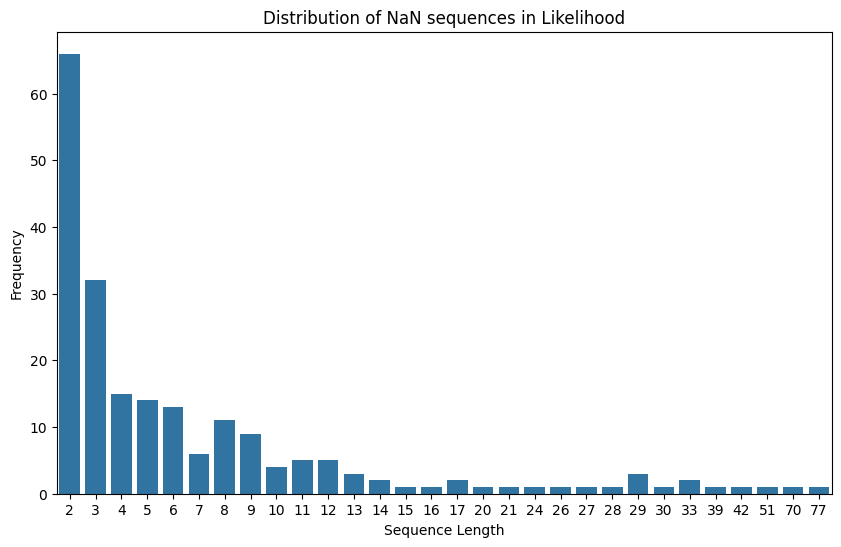

In [160]:
# Initialize variables
nan_counters = {}
current_count = 0
streak_start = None
streaks = []

# Iterate through the rows
for i in range(len(data)):
    if pd.isna(data['likelihood'].iloc[i]):
        if current_count == 0:
            streak_start = i
        current_count += 1
    else:
        if current_count > 1:  # Exclude cases of 1 NaN only
            if current_count in nan_counters:
                nan_counters[current_count] += 1
            else:
                nan_counters[current_count] = 1
            streaks.append((streak_start, current_count))
        current_count = 0

# Handle the case where the last rows are NaNs
if current_count > 1:
    if current_count in nan_counters:
        nan_counters[current_count] += 1
    else:
        nan_counters[current_count] = 1
    streaks.append((streak_start, current_count))

# Convert the dictionary to a DataFrame for easier plotting
nan_streaks_df = pd.DataFrame(nan_counters.items(), columns=['Streak Length', 'Frequency'])

# Add streak start locations to the DataFrame
streak_starts_df = pd.DataFrame(streaks, columns=['Start Index', 'Streak Length'])
nan_streaks_df = nan_streaks_df.merge(streak_starts_df, on='Streak Length', how='left')

# Plot the distribution of NaN streaks
plt.figure(figsize=(10, 6))
sns.barplot(x='Streak Length', y='Frequency', data=nan_streaks_df)
plt.xlabel('Sequence Length')
plt.ylabel('Frequency')
plt.title('Distribution of NaN sequences in Likelihood')
plt.show()

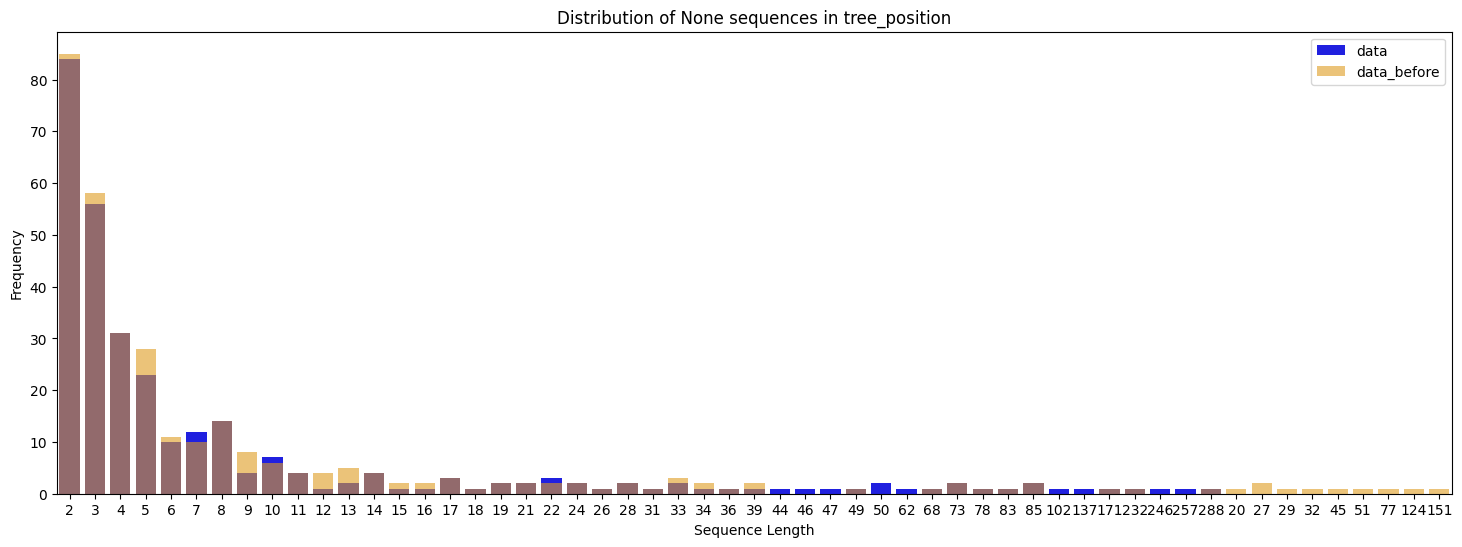

In [163]:
def find_none_sequences(data, column):
    """
    Find sequences of None values in the specified column of the DataFrame.

    Args:
    - data (pd.DataFrame): The DataFrame to search.
    - column (str): The column name to search for None values.

    Returns:
    - dict: A dictionary with sequence lengths as keys and their frequencies as values.
    - list: A list of tuples with the start index and length of each sequence.
    """
    none_counters = {}
    current_count = 0
    streak_start = None
    streaks = []

    # Iterate through the rows
    for i in range(len(data)):
        if data[column].iloc[i] is None:
            if current_count == 0:
                streak_start = i
            current_count += 1
        else:
            if current_count > 1:  # Exclude cases of 1 None only
                if current_count in none_counters:
                    none_counters[current_count] += 1
                else:
                    none_counters[current_count] = 1
                streaks.append((streak_start, current_count))
            current_count = 0

    # Handle the case where the last rows are None
    if current_count > 1:
        if current_count in none_counters:
            none_counters[current_count] += 1
        else:
            none_counters[current_count] = 1
        streaks.append((streak_start, current_count))

    return none_counters, streaks

# Find sequences of None values in the 'tree_position' column
none_counters, none_streaks = find_none_sequences(data, 'tree_position')

# Convert the dictionary to a DataFrame for easier plotting
none_streaks_df = pd.DataFrame(none_counters.items(), columns=['Streak Length', 'Frequency'])
# Find sequences of None values in the 'tree_position' column for data_before
none_counters_before, none_streaks_before = find_none_sequences(data_before, 'tree_position')

# Convert the dictionary to a DataFrame for easier plotting
none_streaks_df_before = pd.DataFrame(none_counters_before.items(), columns=['Streak Length', 'Frequency'])

# Plot the distribution of None sequences for both data and data_before
plt.figure(figsize=(18, 6))
sns.barplot(x='Streak Length', y='Frequency', data=none_streaks_df, color='blue', label='data')
sns.barplot(x='Streak Length', y='Frequency', data=none_streaks_df_before, color='orange', label='data_before', alpha=0.6)
plt.xlabel('Sequence Length')
plt.ylabel('Frequency')
plt.title('Distribution of None sequences in tree_position')
plt.legend()
plt.show()

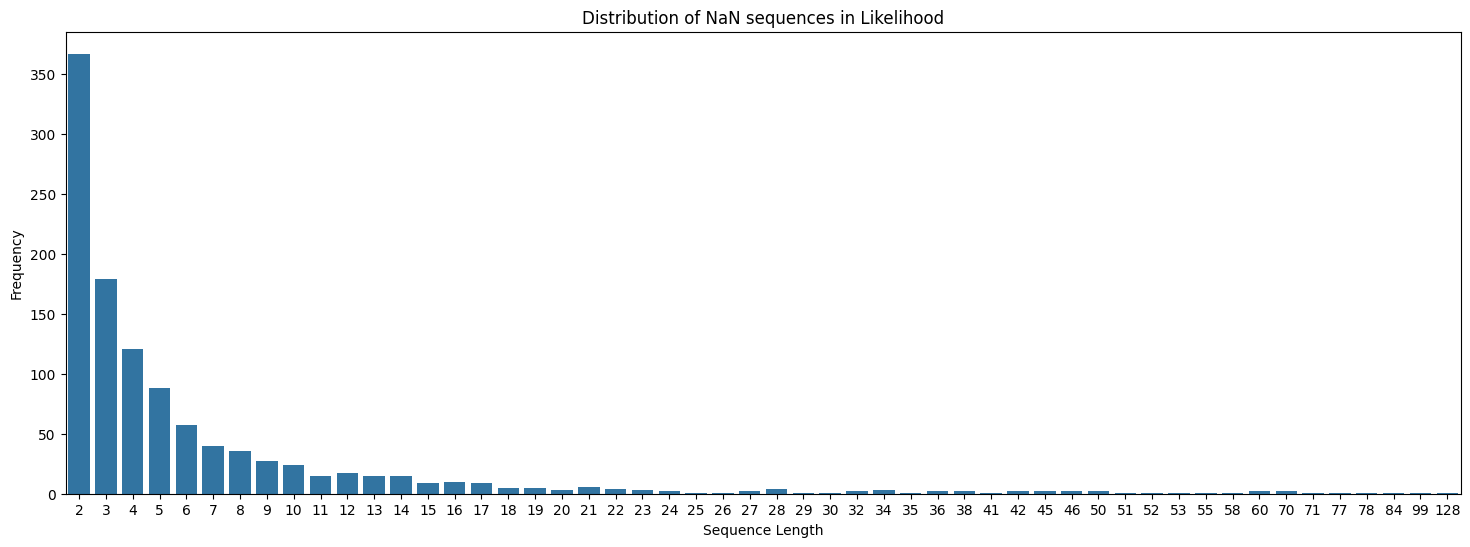

In [165]:
# Initialize variables
nan_counters = {}
current_count = 0
streak_start = None
streaks = []

# Iterate through the rows
for i in range(len(data_before)):
    if pd.isna(data_before['likelihood'].iloc[i]):
        if current_count == 0:
            streak_start = i
        current_count += 1
    else:
        if current_count > 1:  # Exclude cases of 1 NaN only
            if current_count in nan_counters:
                nan_counters[current_count] += 1
            else:
                nan_counters[current_count] = 1
            streaks.append((streak_start, current_count))
        current_count = 0

# Handle the case where the last rows are NaNs
if current_count > 1:
    if current_count in nan_counters:
        nan_counters[current_count] += 1
    else:
        nan_counters[current_count] = 1
    streaks.append((streak_start, current_count))

# Convert the dictionary to a DataFrame for easier plotting
nan_streaks_df = pd.DataFrame(nan_counters.items(), columns=['Streak Length', 'Frequency'])

# Add streak start locations to the DataFrame
streak_starts_df = pd.DataFrame(streaks, columns=['Start Index', 'Streak Length'])
nan_streaks_df = nan_streaks_df.merge(streak_starts_df, on='Streak Length', how='left')

# Plot the distribution of NaN streaks
plt.figure(figsize=(18, 6))
sns.barplot(x='Streak Length', y='Frequency', data=nan_streaks_df)
plt.xlabel('Sequence Length')
plt.ylabel('Frequency')
plt.title('Distribution of NaN sequences in Likelihood')
plt.show()

In [53]:
nan_streaks_df[nan_streaks_df['Streak Length'] > 7]

NameError: name 'nan_streaks_df' is not defined

In [ ]:
dlc_metadata

In [394]:
num_nan_likelihood_rows = data['likelihood'].isna().sum()
print(f"Number of rows where likelihood is NaN: {num_nan_likelihood_rows}")
print(f"Percentage of rows where likelihood is NaN: {num_nan_likelihood_rows / len(data) * 100:.2f}%")

Number of rows where likelihood is NaN: 48
Percentage of rows where likelihood is NaN: 0.05%


In [54]:
data[-100:-50]

coords,x,y,likelihood,tile_box,tile_id,tree_position,graph_node,ear_R_likelihood,ear_L_likelihood,mid_body_likelihood,tail_base_likelihood
100751,1094.107056,403.173798,0.993118,"[918, 307, 31, 31]",158,423,"(25, 9)",0.997599,0.998211,0.996751,0.894515
100752,1095.062256,403.299713,0.992682,"[918, 307, 31, 31]",158,423,"(25, 9)",0.997706,0.998491,0.997436,0.914782
100753,1095.397583,402.932922,0.992667,"[918, 307, 31, 31]",158,423,"(25, 9)",0.997824,0.998434,0.997415,0.930897
100754,1094.895630,403.002472,0.993240,"[918, 307, 31, 31]",158,423,"(25, 9)",0.997758,0.998396,0.997373,0.926905
100755,1094.875244,403.728241,0.992683,"[918, 307, 31, 31]",158,423,"(25, 9)",0.997309,0.998182,0.997456,0.924725
100756,1095.337891,403.402771,0.991575,"[918, 307, 31, 31]",158,423,"(25, 9)",0.996984,0.998393,0.997122,0.949924
100757,1097.948730,405.021057,0.989687,"[918, 307, 31, 31]",158,423,"(25, 9)",0.99522,0.998118,0.997217,0.959757
100758,1100.533203,406.819061,0.991062,"[918, 307, 31, 31]",158,423,"(25, 9)",0.996646,0.997533,0.995804,0.973178
100759,1104.912598,406.419647,0.991046,"[918, 307, 31, 31]",158,423,"(25, 9)",0.99646,0.998109,0.992613,0.98532
100760,1107.921143,405.498962,0.995719,"[950, 307, 31, 31]",159,"(423, 547)","(26, 9)",0.996622,0.998423,0.994645,0.993013


In [ ]:
!pip install tables

In [117]:
h5_file['DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000']['ear_R']

coords,x,y,likelihood
0,1176.851929,536.350891,0.266385
1,1177.178223,536.455383,0.240243
2,1176.497070,536.815491,0.258914
3,1173.995361,534.832764,0.282987
4,1176.438843,536.910706,0.269126
...,...,...,...
100846,1161.398682,424.797394,0.242903
100847,1161.256226,424.281067,0.279702
100848,1161.000122,424.264923,0.282268
100849,1160.645142,422.206757,0.241012


In [ ]:

def calculate_weighted_coordinates(row):
    body_parts = ['ear_R', 'ear_L', 'mid_body', 'tail_base']
    total_weight = 0
    weighted_x = 0
    weighted_y = 0
    weighted_likelihood = 0
    likelihoods = []

    for part in body_parts:
        likelihood = row[f'{part}_likelihood']
        likelihoods.append(likelihood)
        if likelihood > 0:
            weighted_x += row[f'{part}_x'] * likelihood
            weighted_y += row[f'{part}_y'] * likelihood
            total_weight += likelihood

    if total_weight > 0:
        weighted_x /= total_weight
        weighted_y /= total_weight
        weighted_likelihood = sum([likelihood * (likelihood / total_weight) for likelihood in likelihoods])
    likelihoods = []

    return pd.Series([weighted_x, weighted_y, weighted_likelihood])

# Convert relevant columns to numeric types
for part in ['nose', 'ear_R', 'ear_L', 'mid_body', 'tail_base']:
    h5_file[file_name][part].apply(pd.to_numeric)

# Apply the function to each row in the dataframe
h5_file[['weighted_x', 'weighted_y', 'weighted_likelihood']] = h5_file.loc[0:].apply(
    lambda row: calculate_weighted_coordinates(row) if row['nose_likelihood'] < 0.3 else pd.Series([row['nose_x'], row['nose_y'], row['nose_likelihood']]),
    axis=1
)

# Display the updated dataframe
h5_file


In [318]:
file_name = 'DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000'

# Load the DataFrame from the HDF5 file
dlc_raw_h5 = h5_file[file_name]

# Extract the MultiIndex from the first two rows
multi_index = pd.MultiIndex.from_arrays([dlc_raw_h5.iloc[0], dlc_raw_h5.iloc[1]])

# Convert the data to numeric, errors='coerce' will turn non-numeric values into NaN
dlc_raw_h5 = dlc_raw_h5.apply(pd.to_numeric, errors='coerce')

new_index = pd.MultiIndex.from_tuples([
        ('weighted', 'x'),
        ('weighted', 'y'),
        ('weighted', 'likelihood')
    ])

new_index_df = pd.DataFrame(np.nan, index=range(len(dlc_raw_h5)), columns=new_index)


# Concatenate the original DataFrame with the new columns DataFrame
# dlc_raw_h5 = pd.concat([dlc_raw_h5, new_columns], axis=1)

dlc_raw_h5 = pd.concat([dlc_raw_h5, new_index_df], axis=1)
dlc_raw_h5

nose                               ear_R              \
                  x           y likelihood            x           y   
0       1185.160156  538.587524   0.301229  1176.851929  536.350891   
1       1185.624512  538.795898   0.317019  1177.178223  536.455383   
2       1184.983643  538.559937   0.379136  1176.497070  536.815491   
3       1184.867920  538.319458   0.361163  1173.995361  534.832764   
4       1184.941162  538.401123   0.381323  1176.438843  536.910706   
...             ...         ...        ...          ...         ...   
100846  1184.224365  537.869141   0.324106  1161.398682  424.797394   
100847  1184.558838  538.006897   0.348444  1161.256226  424.281067   
100848  1184.719849  538.035400   0.333846  1161.000122  424.264923   
100849  1184.665649  537.941528   0.363440  1160.645142  422.206757   
100850  1184.314087  537.922729   0.371406  1175.253540  537.551758   

                         ear_L                            mid_body  \
       likelihood            x           y likelihood            x   
0        0.266385  1178.337402  532.390625   0.497909  1168.987183   
1        0.240243  1178.435425  532.607361   0.478445  1169.237061   
2        0.258914  1177.749756  532.508057   0.518972  1169.224609   
3        0.282987  1177.754883  532.137085   0.536812  1168.850586   
4        0.269126  1177.820801  532.226501   0.565688  1168.860229   
...           ...          ...         ...        ...          ...   
100846   0.242903  1177.327881  532.284668   0.483810  1153.382324   
100847   0.279702  1177.287598  532.323853   0.506236  1153.304443   
100848   0.282268  1177.296143  532.494934   0.534847  1153.317505   
100849   0.241012  1176.740967  532.460144   0.512872  1153.009033   
100850   0.228917  1176.786377  532.441528   0.535443  1152.989624   

                                 tail_base                        weighted  \
                 y likelihood            x           y likelihood        x   
0       532.761047   0.733766  1158.631836  527.581543   0.364837      NaN   
1       532.961792   0.652495  1159.558350  530.852417   0.342024      NaN   
2       532.765991   0.647291  1159.733276  530.747559   0.259477      NaN   
3       532.734985   0.703636  1158.633545  527.634155   0.322151      NaN   
4       532.741516   0.603395  1159.476807  530.955627   0.275038      NaN   
...            ...        ...          ...         ...        ...      ...   
100846  404.956329   0.981035  1134.431274  392.918152   0.991836      NaN   
100847  404.921539   0.983298  1134.522339  392.664276   0.992491      NaN   
100848  405.013428   0.982606  1134.577026  392.577759   0.993141      NaN   
100849  404.140686   0.982961  1134.431152  392.153290   0.993115      NaN   
100850  404.265442   0.982774  1134.826172  392.895996   0.991002      NaN   

                       
         y likelihood  
0      NaN        NaN  
1      NaN        NaN  
2      NaN        NaN  
3      NaN        NaN  
4      NaN        NaN  
...     ..        ...  
100846 NaN        NaN  
100847 NaN        NaN  
100848 NaN        NaN  
100849 NaN        NaN  
100850 NaN        NaN  

[100851 rows x 18 columns]

In [319]:
def calculate_weighted_coordinates(row):
    body_parts = ['ear_R', 'ear_L', 'mid_body', 'tail_base']
    total_weight = 0
    weighted_x = 0
    weighted_y = 0
    weighted_likelihood = 0
    likelihoods = []

    for part in body_parts:
        likelihood = row[part]['likelihood']
        likelihoods.append(likelihood)
        if likelihood > 0:
            weighted_x += row[part]['x'] * likelihood
            weighted_y += row[part]['y'] * likelihood
            total_weight += likelihood

    if total_weight > 0:
        weighted_x /= total_weight
        weighted_y /= total_weight
        weighted_likelihood = sum([likelihood * (likelihood / total_weight) for likelihood in likelihoods])
    likelihoods = []

    return (weighted_x, weighted_y, weighted_likelihood)

# # Apply the function to each row in the dataframe
# dlc_raw_h5['weighted'][['x', 'y', 'likelihood']] = dlc_raw_h5.apply(
#     lambda row: calculate_weighted_coordinates(row) if row['nose']['likelihood'] < 0.3 else pd.Series([row['nose']['x'], row['nose']['y'], row['nose']['likelihood']]),
#     axis=1
# )

for i, row in enumerate(dlc_raw_h5.iterrows()):
    if row[1]['nose']['likelihood'] >= 0.3:
        dlc_raw_h5.loc[i, ('weighted', ['x', 'y', 'likelihood'])] = (row[1]['nose']['x'], row[1]['nose']['y'], row[1]['nose']['likelihood'])
    else:
        dlc_raw_h5.loc[i, ('weighted', ['x', 'y', 'likelihood'])] = calculate_weighted_coordinates(row[1])

# Display the updated dataframe
dlc_raw_h5


nose                               ear_R              \
                  x           y likelihood            x           y   
0       1185.160156  538.587524   0.301229  1176.851929  536.350891   
1       1185.624512  538.795898   0.317019  1177.178223  536.455383   
2       1184.983643  538.559937   0.379136  1176.497070  536.815491   
3       1184.867920  538.319458   0.361163  1173.995361  534.832764   
4       1184.941162  538.401123   0.381323  1176.438843  536.910706   
...             ...         ...        ...          ...         ...   
100846  1184.224365  537.869141   0.324106  1161.398682  424.797394   
100847  1184.558838  538.006897   0.348444  1161.256226  424.281067   
100848  1184.719849  538.035400   0.333846  1161.000122  424.264923   
100849  1184.665649  537.941528   0.363440  1160.645142  422.206757   
100850  1184.314087  537.922729   0.371406  1175.253540  537.551758   

                         ear_L                            mid_body  \
       likelihood            x           y likelihood            x   
0        0.266385  1178.337402  532.390625   0.497909  1168.987183   
1        0.240243  1178.435425  532.607361   0.478445  1169.237061   
2        0.258914  1177.749756  532.508057   0.518972  1169.224609   
3        0.282987  1177.754883  532.137085   0.536812  1168.850586   
4        0.269126  1177.820801  532.226501   0.565688  1168.860229   
...           ...          ...         ...        ...          ...   
100846   0.242903  1177.327881  532.284668   0.483810  1153.382324   
100847   0.279702  1177.287598  532.323853   0.506236  1153.304443   
100848   0.282268  1177.296143  532.494934   0.534847  1153.317505   
100849   0.241012  1176.740967  532.460144   0.512872  1153.009033   
100850   0.228917  1176.786377  532.441528   0.535443  1152.989624   

                                 tail_base                         \
                 y likelihood            x           y likelihood   
0       532.761047   0.733766  1158.631836  527.581543   0.364837   
1       532.961792   0.652495  1159.558350  530.852417   0.342024   
2       532.765991   0.647291  1159.733276  530.747559   0.259477   
3       532.734985   0.703636  1158.633545  527.634155   0.322151   
4       532.741516   0.603395  1159.476807  530.955627   0.275038   
...            ...        ...          ...         ...        ...   
100846  404.956329   0.981035  1134.431274  392.918152   0.991836   
100847  404.921539   0.983298  1134.522339  392.664276   0.992491   
100848  405.013428   0.982606  1134.577026  392.577759   0.993141   
100849  404.140686   0.982961  1134.431152  392.153290   0.993115   
100850  404.265442   0.982774  1134.826172  392.895996   0.991002   

           weighted                         
                  x           y likelihood  
0       1185.160156  538.587524   0.301229  
1       1185.624512  538.795898   0.317019  
2       1184.983643  538.559937   0.379136  
3       1184.867920  538.319458   0.361163  
4       1184.941162  538.401123   0.381323  
...             ...         ...        ...  
100846  1184.224365  537.869141   0.324106  
100847  1184.558838  538.006897   0.348444  
100848  1184.719849  538.035400   0.333846  
100849  1184.665649  537.941528   0.363440  
100850  1184.314087  537.922729   0.371406  

[100851 rows x 18 columns]

In [320]:
dlc_raw_h5[dlc_raw_h5['nose']['likelihood'] < 0.3]

nose                               ear_R              \
                  x           y likelihood            x           y   
13      1184.540283  538.019653   0.277739  1176.146973  536.267578   
66      1184.286255  538.215881   0.298321  1173.708984  534.768066   
356      246.989670  774.850464   0.295188   252.990768  780.463440   
1217    1183.764404  537.737610   0.274668   242.469009  769.175110   
1904    1183.963501  537.473083   0.290055   965.347534  575.260315   
...             ...         ...        ...          ...         ...   
100829  1184.720825  538.334473   0.290947  1160.911743  423.205627   
100833  1184.466919  537.952759   0.298018  1160.513306  422.444305   
100837  1184.229858  538.384399   0.275419  1160.921509  422.915253   
100841  1184.257690  537.963928   0.289764  1161.000000  423.889893   
100845  1184.736328  538.398132   0.255786  1160.579224  422.700287   

                         ear_L                            mid_body  \
       likelihood            x           y likelihood            x   
13       0.162247  1177.154541  532.027283   0.318151  1168.963379   
66       0.183036  1177.008057  531.894409   0.361103  1168.483887   
356      0.290671   248.876678  781.546326   0.391331   265.486633   
1217     0.391352  1176.353760  531.643250   0.305030   246.151825   
1904     0.319956   956.495911  583.919006   0.414057   966.582703   
...           ...          ...         ...        ...          ...   
100829   0.217152  1177.347656  532.229370   0.437034  1152.977051   
100833   0.193256  1176.799438  531.865356   0.341747  1152.986084   
100837   0.227914  1177.166260  531.897583   0.340868  1152.841064   
100841   0.281616  1176.785400  532.200500   0.359076  1152.936646   
100845   0.258181  1177.369629  532.257385   0.335558  1152.599487   

                                 tail_base                         \
                 y likelihood            x           y likelihood   
13      532.574890   0.463437  1168.152588  456.034332   0.246900   
66      532.617920   0.467058  1158.567871  527.441223   0.172175   
356     791.974792   0.990978   273.844604  798.942688   0.790156   
1217    783.891541   0.994297   233.384201  795.705139   0.726225   
1904    607.112793   0.990379   958.392334  642.608215   0.942268   
...            ...        ...          ...         ...        ...   
100829  404.377960   0.980796  1134.375610  392.294739   0.993198   
100833  404.337830   0.983216  1134.038696  392.454529   0.991649   
100837  404.174896   0.982508  1134.254150  392.232513   0.992343   
100841  404.451141   0.982186  1134.400635  392.772888   0.992440   
100845  404.113586   0.982826  1134.487427  392.413116   0.991577   

           weighted                         
                  x           y likelihood  
13      1171.962670  517.061002   0.338680  
66      1170.450469  531.976529   0.347891  
356      264.054287  791.194785   0.748645  
1217     359.116876  753.222894   0.729127  
1904     961.974232  612.232030   0.803453  
...             ...         ...        ...  
100829  1150.655641  422.627437   0.831966  
100833  1149.322022  418.401254   0.838379  
100837  1149.573585  418.310899   0.832747  
100841  1150.045376  419.652381   0.825089  
100845  1149.645030  418.208013   0.828781  

[559 rows x 18 columns]

In [321]:
h5_file = pd.concat({file_name: dlc_raw_h5}, axis=1)
# h5_file.rename(mapper={h5_file.columns.names: ['scorer', 'bodtparts', 'coords']}, level=0, inplace=True)
h5_file.columns.names = ['scorer', 'bodyparts', 'coords']
h5_file

scorer    DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000              \
bodyparts                                          nose               
coords                                                x           y   
0                                           1185.160156  538.587524   
1                                           1185.624512  538.795898   
2                                           1184.983643  538.559937   
3                                           1184.867920  538.319458   
4                                           1184.941162  538.401123   
...                                                 ...         ...   
100846                                      1184.224365  537.869141   
100847                                      1184.558838  538.006897   
100848                                      1184.719849  538.035400   
100849                                      1184.665649  537.941528   
100850                                      1184.314087  537.922729   

scorer                                                                 \
bodyparts                   ear_R                               ear_L   
coords    likelihood            x           y likelihood            x   
0           0.301229  1176.851929  536.350891   0.266385  1178.337402   
1           0.317019  1177.178223  536.455383   0.240243  1178.435425   
2           0.379136  1176.497070  536.815491   0.258914  1177.749756   
3           0.361163  1173.995361  534.832764   0.282987  1177.754883   
4           0.381323  1176.438843  536.910706   0.269126  1177.820801   
...              ...          ...         ...        ...          ...   
100846      0.324106  1161.398682  424.797394   0.242903  1177.327881   
100847      0.348444  1161.256226  424.281067   0.279702  1177.287598   
100848      0.333846  1161.000122  424.264923   0.282268  1177.296143   
100849      0.363440  1160.645142  422.206757   0.241012  1176.740967   
100850      0.371406  1175.253540  537.551758   0.228917  1176.786377   

scorer                                                                \
bodyparts                            mid_body                          
coords              y likelihood            x           y likelihood   
0          532.390625   0.497909  1168.987183  532.761047   0.733766   
1          532.607361   0.478445  1169.237061  532.961792   0.652495   
2          532.508057   0.518972  1169.224609  532.765991   0.647291   
3          532.137085   0.536812  1168.850586  532.734985   0.703636   
4          532.226501   0.565688  1168.860229  532.741516   0.603395   
...               ...        ...          ...         ...        ...   
100846     532.284668   0.483810  1153.382324  404.956329   0.981035   
100847     532.323853   0.506236  1153.304443  404.921539   0.983298   
100848     532.494934   0.534847  1153.317505  405.013428   0.982606   
100849     532.460144   0.512872  1153.009033  404.140686   0.982961   
100850     532.441528   0.535443  1152.989624  404.265442   0.982774   

scorer                                                                  \
bodyparts    tail_base                            weighted               
coords               x           y likelihood            x           y   
0          1158.631836  527.581543   0.364837  1185.160156  538.587524   
1          1159.558350  530.852417   0.342024  1185.624512  538.795898   
2          1159.733276  530.747559   0.259477  1184.983643  538.559937   
3          1158.633545  527.634155   0.322151  1184.867920  538.319458   
4          1159.476807  530.955627   0.275038  1184.941162  538.401123   
...                ...         ...        ...          ...         ...   
100846     1134.431274  392.918152   0.991836  1184.224365  537.869141   
100847     1134.522339  392.664276   0.992491  1184.558838  538.006897   
100848     1134.577026  392.577759   0.993141  1184.719849  538.035400   
100849     1134.431152  392.153290   0.993115  1184.665649  537.941528   
100850     

In [322]:
# Save the updated DataFrame back to the HDF5 file
file_name = 'DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000'

h5_file.to_hdf('/var/home/almogmeir/Documents/M.Sc/Project/test.h5', key=file_name, mode='w')

In [323]:
new_h5 = pd.read_hdf('/var/home/almogmeir/Documents/M.Sc/Project/test.h5')
new_h5

scorer    DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000              \
bodyparts                                          nose               
coords                                                x           y   
0                                           1185.160156  538.587524   
1                                           1185.624512  538.795898   
2                                           1184.983643  538.559937   
3                                           1184.867920  538.319458   
4                                           1184.941162  538.401123   
...                                                 ...         ...   
100846                                      1184.224365  537.869141   
100847                                      1184.558838  538.006897   
100848                                      1184.719849  538.035400   
100849                                      1184.665649  537.941528   
100850                                      1184.314087  537.922729   

scorer                                                                 \
bodyparts                   ear_R                               ear_L   
coords    likelihood            x           y likelihood            x   
0           0.301229  1176.851929  536.350891   0.266385  1178.337402   
1           0.317019  1177.178223  536.455383   0.240243  1178.435425   
2           0.379136  1176.497070  536.815491   0.258914  1177.749756   
3           0.361163  1173.995361  534.832764   0.282987  1177.754883   
4           0.381323  1176.438843  536.910706   0.269126  1177.820801   
...              ...          ...         ...        ...          ...   
100846      0.324106  1161.398682  424.797394   0.242903  1177.327881   
100847      0.348444  1161.256226  424.281067   0.279702  1177.287598   
100848      0.333846  1161.000122  424.264923   0.282268  1177.296143   
100849      0.363440  1160.645142  422.206757   0.241012  1176.740967   
100850      0.371406  1175.253540  537.551758   0.228917  1176.786377   

scorer                                                                \
bodyparts                            mid_body                          
coords              y likelihood            x           y likelihood   
0          532.390625   0.497909  1168.987183  532.761047   0.733766   
1          532.607361   0.478445  1169.237061  532.961792   0.652495   
2          532.508057   0.518972  1169.224609  532.765991   0.647291   
3          532.137085   0.536812  1168.850586  532.734985   0.703636   
4          532.226501   0.565688  1168.860229  532.741516   0.603395   
...               ...        ...          ...         ...        ...   
100846     532.284668   0.483810  1153.382324  404.956329   0.981035   
100847     532.323853   0.506236  1153.304443  404.921539   0.983298   
100848     532.494934   0.534847  1153.317505  405.013428   0.982606   
100849     532.460144   0.512872  1153.009033  404.140686   0.982961   
100850     532.441528   0.535443  1152.989624  404.265442   0.982774   

scorer                                                                  \
bodyparts    tail_base                            weighted               
coords               x           y likelihood            x           y   
0          1158.631836  527.581543   0.364837  1185.160156  538.587524   
1          1159.558350  530.852417   0.342024  1185.624512  538.795898   
2          1159.733276  530.747559   0.259477  1184.983643  538.559937   
3          1158.633545  527.634155   0.322151  1184.867920  538.319458   
4          1159.476807  530.955627   0.275038  1184.941162  538.401123   
...                ...         ...        ...          ...         ...   
100846     1134.431274  392.918152   0.991836  1184.224365  537.869141   
100847     1134.522339  392.664276   0.992491  1184.558838  538.006897   
100848     1134.577026  392.577759   0.993141  1184.719849  538.035400   
100849     1134.431152  392.153290   0.993115  1184.665649  537.941528   
100850     